# BlinkIT Grocery Sales Analysis

This project looks at BlinkIT grocery sales data (8,523 records, 12 columns) for a data analyst role at Sapphire IQ. The aim is to understand how the business is performing across products, categories, outlets and locations, check that the data is reliable, find out what drives sales and give practical suggestions for management.

**Tools used:** Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook

**Dataset:** `BlinkIT Grocery Data.xlsx`, one row for each product sold in an outlet. The columns are item details (fat content, identifier, type, visibility, weight), outlet details (identifier, establishment year, size, location type, type), `Sales` and `Rating`.

**How the notebook is organised:** four objectives, each split into tasks. Every code cell has a short explanation above it, and every task ends with what I found.

**To run it:** keep the Excel file in the same folder as this notebook and run the cells from top to bottom.

## Setup

Importing the libraries and loading the data.

**What this code does**

First I import the libraries I need. `pandas` and `numpy` are for working with the data, `matplotlib` and `seaborn` are for the charts. I also switch off warnings so the output stays clean. The last line reads the Excel file into a table called `df`. The Excel file has to be in the same folder as this notebook.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

df = pd.read_excel('BlinkIT Grocery Data.xlsx')

**What this code does**

This only sets how the charts look: a light grid in the background and a clear picture quality (dpi 100).

In [12]:
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

**What this code does**

`df.shape` gives the number of rows and columns, and `df.head()` shows the first 5 rows so I can see what the data looks like.

In [13]:
print("Rows, Columns:", df.shape)
df.head()

Rows, Columns: (8523, 12)


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


**What this code does**

`df.info()` lists every column with its data type and how many values are filled in. This is where I first noticed that `Item Weight` has fewer values than the other columns.

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


## Objective 1: Understand the Business and Its Sales Performance

### Task 1.1: Understand what types of products BlinkIT is selling

**What this code does**

This cell gives a first picture of the products. It counts the total records, the unique products (using `Item Identifier`) and the number of categories (`Item Type`). Then `groupby("Item Type")` puts all rows of the same category together, so I can count the records and unique products in each one and work out each category's share of the total in percent.

In [15]:
print("=" * 60)
print("TASK 1.1: PRODUCT TYPES SOLD BY BLINKIT")
print("=" * 60)

print("Total product records      :", len(df))
print("Unique products (Item ID)  :", df["Item Identifier"].nunique())
print("Product categories (Type)  :", df["Item Type"].nunique())

item_type_summary = (
    df.groupby("Item Type")
      .agg(Records=("Item Identifier", "count"),
           Unique_Products=("Item Identifier", "nunique"))
      .sort_values("Records", ascending=False)
)
item_type_summary["Share_%"] = (item_type_summary["Records"] / len(df) * 100).round(2)
item_type_summary

TASK 1.1: PRODUCT TYPES SOLD BY BLINKIT
Total product records      : 8523
Unique products (Item ID)  : 1559
Product categories (Type)  : 16


,Records,Unique_Products,Share_%
Item Type,,,
Fruits and Vegetables,1232,220,14.46
Snack Foods,1200,220,14.08
Household,910,170,10.68
Frozen Foods,856,155,10.04
Dairy,682,125,8.00
Canned,649,120,7.61
Baking Goods,648,119,7.60
Health and Hygiene,520,95,6.10
Soft Drinks,445,80,5.22


**What this code does**

A bar chart of the table above. `countplot` counts the rows for each Item Type, `order` sorts the bars from biggest to smallest and `bar_label` writes the number on top of each bar.

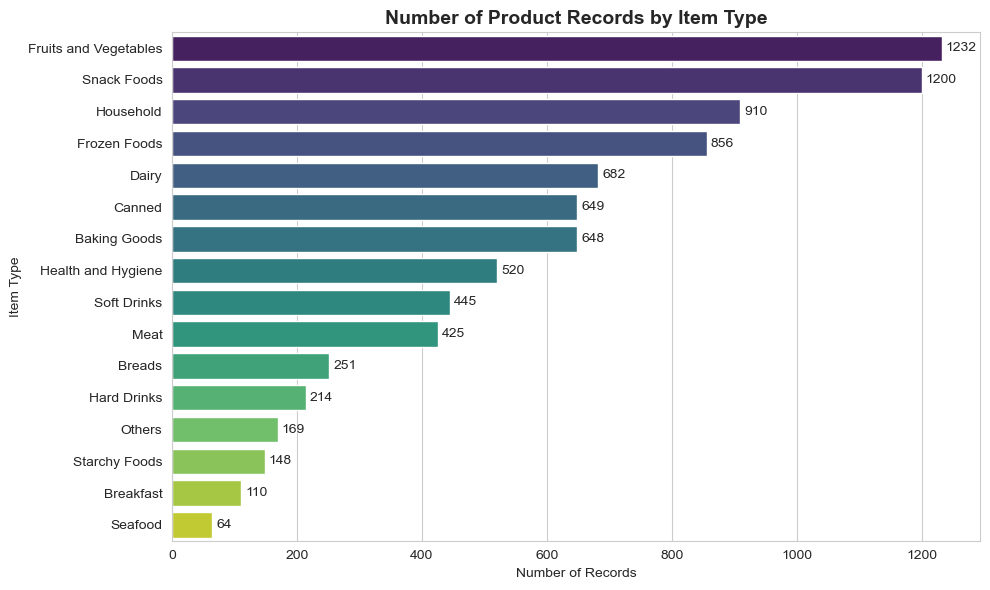

In [16]:
# Visualization 1.1: Product categories by number of records
plt.figure(figsize=(10, 6))
order = df["Item Type"].value_counts().index
ax = sns.countplot(data=df, y="Item Type", order=order, palette="viridis")
for c in ax.containers:
    ax.bar_label(c, padding=3)
plt.title("Number of Product Records by Item Type", fontsize=14, fontweight="bold")
plt.xlabel("Number of Records")
plt.ylabel("Item Type")
plt.tight_layout()
plt.show()

### Task 1.2: Understand the different types and locations of BlinkIT outlets

**What this code does**

Every outlet appears many times in the data, once for each product it sells. `drop_duplicates("Outlet Identifier")` keeps only one row per outlet, so I get a small table of the 10 outlets with their type, location, size and establishment year. This uses the raw data, so the outlet sizes are not cleaned yet. That is fixed later in Objective 2.

In [17]:
print("=" * 60)
print("TASK 1.2: OUTLET TYPES AND LOCATIONS")
print("=" * 60)

outlets = df.drop_duplicates("Outlet Identifier")[
    ["Outlet Identifier", "Outlet Type", "Outlet Location Type",
     "Outlet Size", "Outlet Establishment Year"]
].sort_values("Outlet Identifier").reset_index(drop=True)

print("Total unique outlets:", outlets.shape[0])
outlets

TASK 1.2: OUTLET TYPES AND LOCATIONS
Total unique outlets: 10


,Outlet Identifier,Outlet Type,Outlet Location Type,Outlet Size,Outlet Establishment Year
0,OUT010,Grocery Store,Tier 3,Small,2011
1,OUT013,Supermarket Type1,Tier 3,High,2014
2,OUT017,Supermarket Type1,Tier 2,Small,2020
3,OUT018,Supermarket Type2,Tier 3,Medium,2022
4,OUT019,Grocery Store,Tier 1,Small,2018
5,OUT027,Supermarket Type3,Tier 3,Medium,2018
6,OUT035,Supermarket Type1,Tier 2,Small,2017
7,OUT045,Supermarket Type1,Tier 2,Small,2015
8,OUT046,Supermarket Type1,Tier 1,Small,2016
9,OUT049,Supermarket Type1,Tier 1,Medium,2012


**What this code does**

`value_counts()` counts how many outlets there are of each type, location and size. The `crosstab` at the end puts Outlet Type against Location Type, for example how many Supermarket Type1 outlets are in Tier 3.

In [18]:
print("Outlets by Type     :\n", outlets["Outlet Type"].value_counts(), "\n")
print("Outlets by Location :\n", outlets["Outlet Location Type"].value_counts(), "\n")
print("Outlets by Size     :\n", outlets["Outlet Size"].value_counts(), "\n")

print("Outlet Type vs Location Type (number of outlets):")
pd.crosstab(outlets["Outlet Type"], outlets["Outlet Location Type"], margins=True)

Outlets by Type     :
 Outlet Type
Supermarket Type1    6
Grocery Store        2
Supermarket Type2    1
Supermarket Type3    1
Name: count, dtype: int64 

Outlets by Location :
 Outlet Location Type
Tier 3    4
Tier 2    3
Tier 1    3
Name: count, dtype: int64 

Outlets by Size     :
 Outlet Size
Small     6
Medium    3
High      1
Name: count, dtype: int64 

Outlet Type vs Location Type (number of outlets):


Outlet Location Type,Tier 1,Tier 2,Tier 3,All
Outlet Type,,,,
Grocery Store,1,0,1,2
Supermarket Type1,2,3,1,6
Supermarket Type2,0,0,1,1
Supermarket Type3,0,0,1,1
All,3,3,4,10


**What this code does**

Four small bar charts in one picture (2 x 2): outlets by type, location, size and establishment year. The loop draws the first three charts. The fourth is drawn separately because it uses a different column.

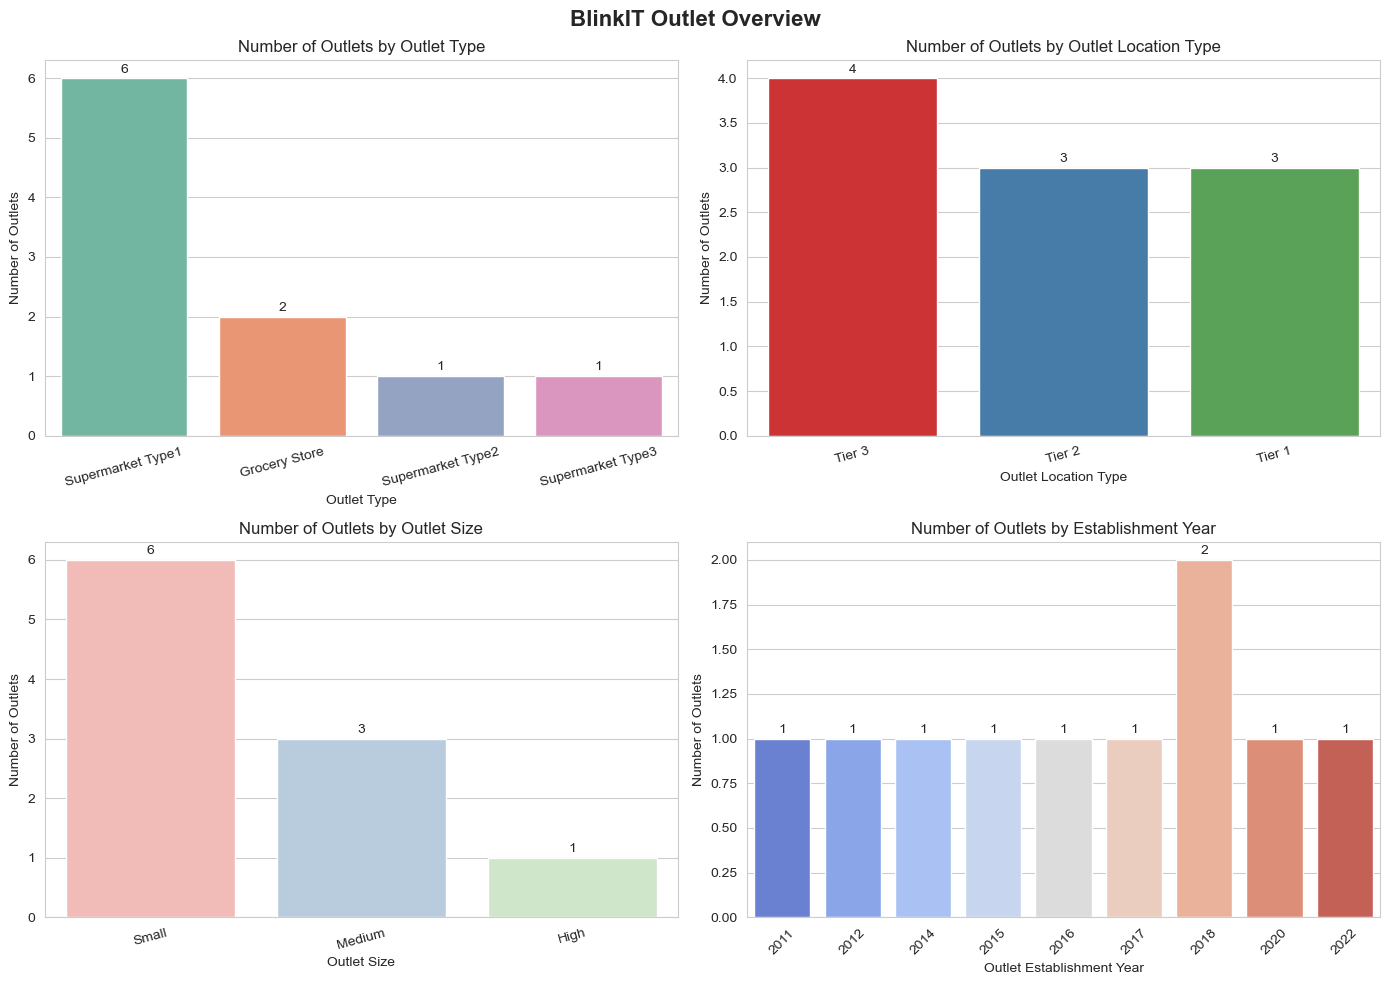

In [19]:
# Visualization 1.2: Outlets by type, location, size and establishment year
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("BlinkIT Outlet Overview", fontsize=16, fontweight="bold")

for ax, col, pal in zip(axes.flatten()[:3],
                        ["Outlet Type", "Outlet Location Type", "Outlet Size"],
                        ["Set2", "Set1", "Pastel1"]):
    sns.countplot(data=outlets, x=col, palette=pal, ax=ax,
                  order=outlets[col].value_counts().index)
    for c in ax.containers:
        ax.bar_label(c, padding=2)
    ax.set_title(f"Number of Outlets by {col}")
    ax.set_ylabel("Number of Outlets")
    ax.tick_params(axis="x", rotation=15)

sns.countplot(data=outlets, x="Outlet Establishment Year", palette="coolwarm", ax=axes[1, 1])
for c in axes[1, 1].containers:
    axes[1, 1].bar_label(c, padding=2)
axes[1, 1].set_title("Number of Outlets by Establishment Year")
axes[1, 1].set_ylabel("Number of Outlets")
axes[1, 1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### Task 1.3: Understand how much BlinkIT is selling overall

**What this code does**

This cell shows how much BlinkIT sold overall. It prints the total, average, median, minimum, maximum and standard deviation of `Sales` (the standard deviation tells how spread out the sales are). `describe()` at the end gives the same numbers plus the 25%, 50% and 75% points in one table.

In [20]:
print("=" * 60)
print("TASK 1.3: OVERALL SALES")
print("=" * 60)

print(f"Total Sales     : {df['Sales'].sum():,.2f}")
print(f"Average Sales   : {df['Sales'].mean():,.2f}")
print(f"Median Sales    : {df['Sales'].median():,.2f}")
print(f"Minimum Sales   : {df['Sales'].min():,.2f}")
print(f"Maximum Sales   : {df['Sales'].max():,.2f}")
print(f"Std. Deviation  : {df['Sales'].std():,.2f}")

df["Sales"].describe().round(2)

TASK 1.3: OVERALL SALES
Total Sales     : 1,201,681.49
Average Sales   : 140.99
Median Sales    : 143.01
Minimum Sales   : 31.29
Maximum Sales   : 266.89
Std. Deviation  : 62.28


count    8523.00
mean      140.99
std        62.28
min        31.29
25%        93.83
50%       143.01
75%       185.64
max       266.89
Name: Sales, dtype: float64

**What this code does**

Two charts for the Sales column. The histogram on the left shows how many sales fall in each range, with a red line for the mean and an orange line for the median. The boxplot on the right shows the spread of the sales and any outliers.

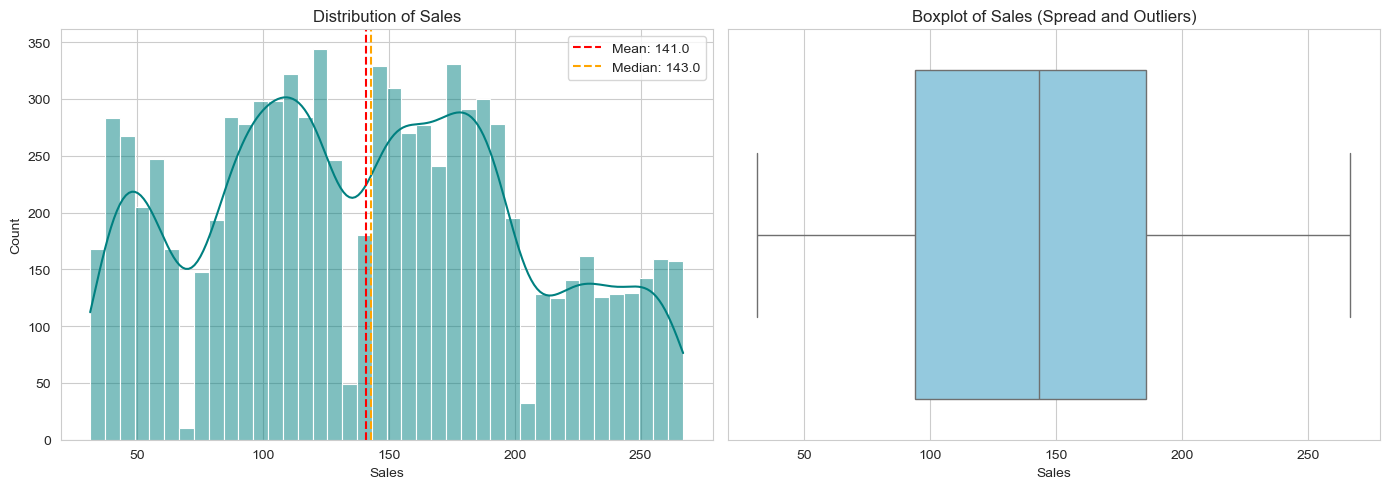

In [21]:
# Visualization 1.3: Distribution of sales
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["Sales"], bins=40, kde=True, color="teal", ax=axes[0])
axes[0].axvline(df["Sales"].mean(), color="red", linestyle="--", label=f"Mean: {df['Sales'].mean():.1f}")
axes[0].axvline(df["Sales"].median(), color="orange", linestyle="--", label=f"Median: {df['Sales'].median():.1f}")
axes[0].set_title("Distribution of Sales")
axes[0].set_xlabel("Sales")
axes[0].legend()

sns.boxplot(x=df["Sales"], color="skyblue", ax=axes[1])
axes[1].set_title("Boxplot of Sales (Spread and Outliers)")
axes[1].set_xlabel("Sales")

plt.tight_layout()
plt.show()

### Task 1.4: Understand the overall customer rating and product performance

**What this code does**

This looks at customer ratings and at how each product category performs. First the average, median, minimum and maximum rating, then `value_counts()` to see how many rows have each rating value. After that I group by `Item Type` and calculate total sales, average sales and average rating for every category.

In [22]:
print("=" * 60)
print("TASK 1.4: CUSTOMER RATING AND PRODUCT PERFORMANCE")
print("=" * 60)

print(f"Average Rating : {df['Rating'].mean():.2f}")
print(f"Median Rating  : {df['Rating'].median():.2f}")
print(f"Min / Max      : {df['Rating'].min()} / {df['Rating'].max()}")

print("\nRating value counts:")
print(df["Rating"].value_counts().sort_index())

product_perf = (
    df.groupby("Item Type")
      .agg(Total_Sales=("Sales", "sum"),
           Avg_Sales=("Sales", "mean"),
           Avg_Rating=("Rating", "mean"))
      .round(2)
      .sort_values("Total_Sales", ascending=False)
)
print("\nProduct performance by Item Type:")
product_perf

TASK 1.4: CUSTOMER RATING AND PRODUCT PERFORMANCE
Average Rating : 3.97
Median Rating  : 4.00
Min / Max      : 1.0 / 5.0

Rating value counts:
Rating
1.0     114
1.2       1
1.3       2
1.4       1
1.5      11
1.7       8
1.8       5
1.9       2
2.0      74
2.1       4
2.2       9
2.3      26
2.4      11
2.5      48
2.6      14
2.7      21
2.8      49
2.9      24
3.0     193
3.1      49
3.2      55
3.3     121
3.4      83
3.5     171
3.6     150
3.7     211
3.8     253
3.9     302
4.0    3339
4.1     524
4.2     673
4.3     694
4.4     340
4.5     256
4.6     102
4.7      79
4.8      62
4.9      15
5.0     427
Name: count, dtype: int64

Product performance by Item Type:


,Total_Sales,Avg_Sales,Avg_Rating
Item Type,,,
Fruits and Vegetables,178124.08,144.58,3.96
Snack Foods,175433.92,146.19,3.95
Household,135976.53,149.42,4.00
Frozen Foods,118558.88,138.50,3.97
Dairy,101276.46,148.50,3.97
Canned,90706.73,139.76,3.99
Baking Goods,81894.74,126.38,3.98
Health and Hygiene,68025.84,130.82,3.99
Meat,59449.86,139.88,4.02


**What this code does**

The same two chart types as before (histogram and boxplot), this time for `Rating`. The red line is the average rating.

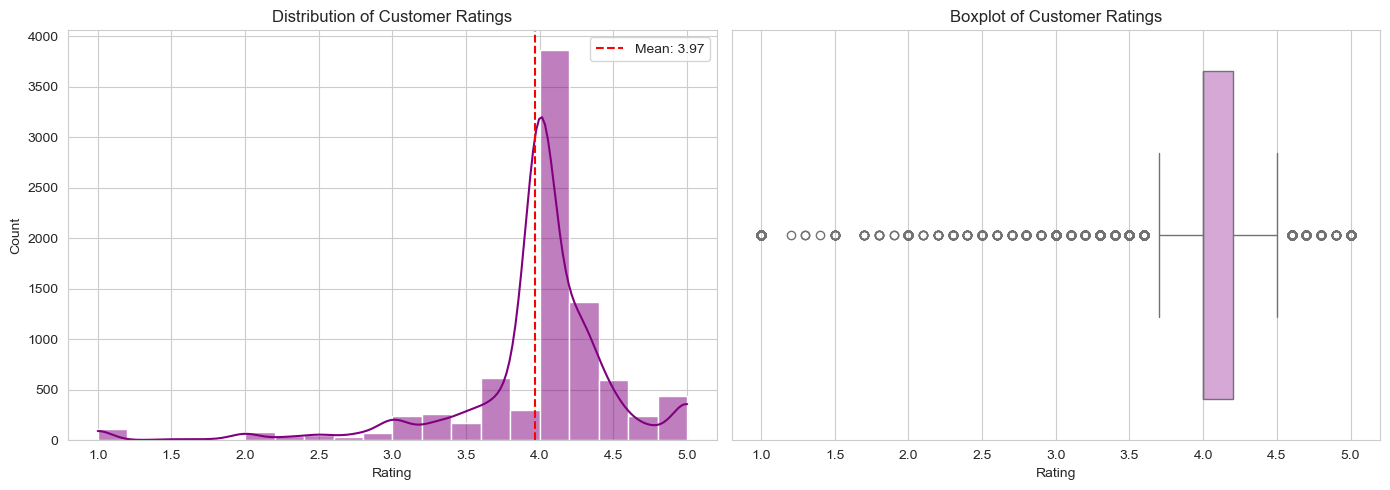

In [23]:
# Visualization 1.4a: Rating distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["Rating"], bins=20, kde=True, color="purple", ax=axes[0])
axes[0].axvline(df["Rating"].mean(), color="red", linestyle="--", label=f"Mean: {df['Rating'].mean():.2f}")
axes[0].set_title("Distribution of Customer Ratings")
axes[0].set_xlabel("Rating")
axes[0].legend()

sns.boxplot(x=df["Rating"], color="plum", ax=axes[1])
axes[1].set_title("Boxplot of Customer Ratings")
axes[1].set_xlabel("Rating")

plt.tight_layout()
plt.show()

**What this code does**

Two bar charts side by side. On the left is total sales for each category and on the right the average rating for each category. `set_xlim` zooms the rating axis, because all the averages are close to each other and would otherwise look the same.

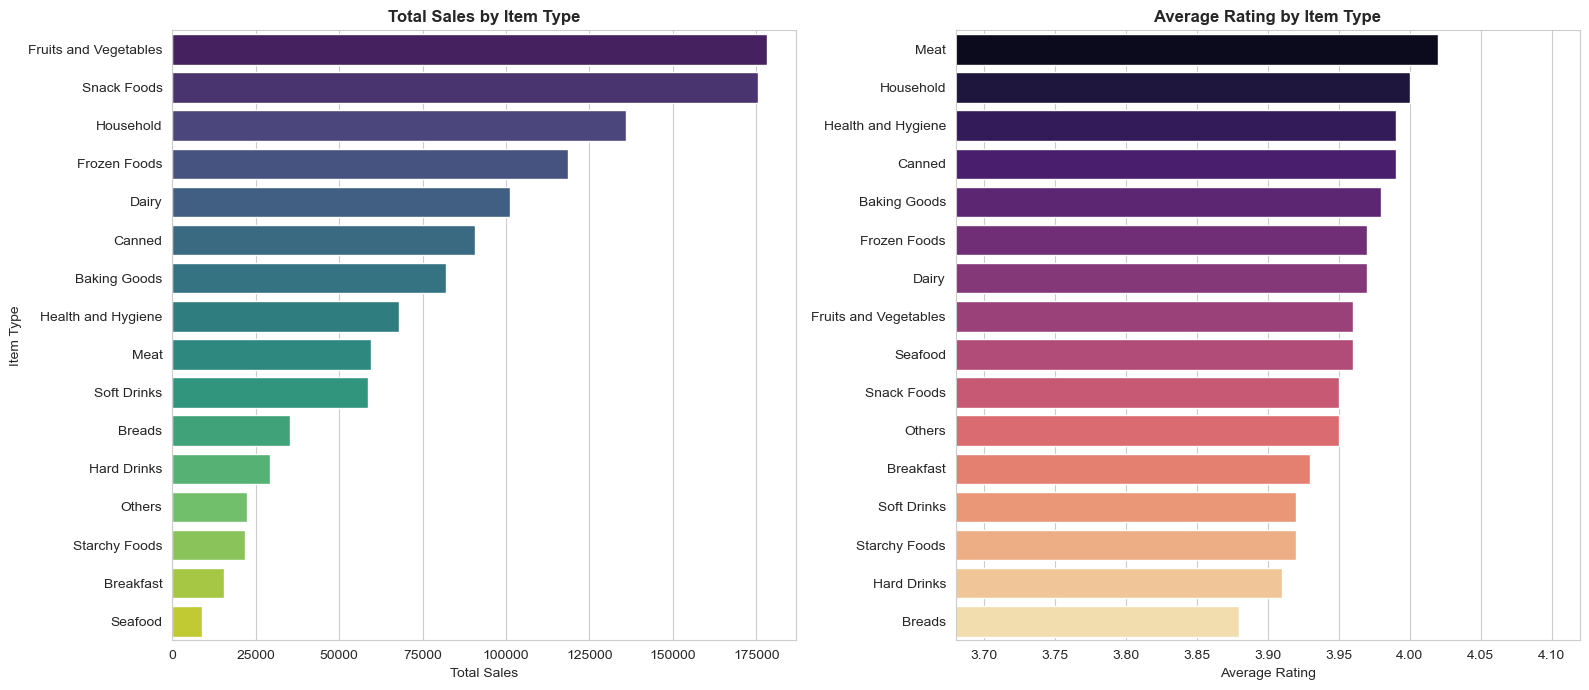

In [24]:
# Visualization 1.4b: Total sales and average rating by Item Type
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(x=product_perf["Total_Sales"], y=product_perf.index, palette="viridis", ax=axes[0])
axes[0].set_title("Total Sales by Item Type", fontweight="bold")
axes[0].set_xlabel("Total Sales")
axes[0].set_ylabel("Item Type")

rating_order = product_perf.sort_values("Avg_Rating", ascending=False)
sns.barplot(x=rating_order["Avg_Rating"], y=rating_order.index, palette="magma", ax=axes[1])
axes[1].set_title("Average Rating by Item Type", fontweight="bold")
axes[1].set_xlabel("Average Rating")
axes[1].set_ylabel("")
axes[1].set_xlim(rating_order["Avg_Rating"].min() - 0.2, rating_order["Avg_Rating"].max() + 0.1)

plt.tight_layout()
plt.show()

**What this code does**

`head(5)` and `tail(5)` take the first and last five rows of the sorted table. So this shows the 5 categories with the highest sales and the 5 with the lowest.

In [25]:
# Top 5 and Bottom 5 item types by total sales
print("Top 5 Item Types by Total Sales:")
print(product_perf.head(5)[["Total_Sales", "Avg_Rating"]], "\n")
print("Bottom 5 Item Types by Total Sales:")
print(product_perf.tail(5)[["Total_Sales", "Avg_Rating"]])

Top 5 Item Types by Total Sales:
                       Total_Sales  Avg_Rating
Item Type                                     
Fruits and Vegetables    178124.08        3.96
Snack Foods              175433.92        3.95
Household                135976.53        4.00
Frozen Foods             118558.88        3.97
Dairy                    101276.46        3.97 

Bottom 5 Item Types by Total Sales:
               Total_Sales  Avg_Rating
Item Type                             
Hard Drinks       29334.68        3.91
Others            22451.89        3.95
Starchy Foods     21880.03        3.92
Breakfast         15596.70        3.93
Seafood            9077.87        3.96


**What I found**

- BlinkIT has 8,523 records, 1,559 unique products and 16 categories in total.
- 10 outlets: 6 Supermarket Type1, 2 Grocery Stores, 1 Supermarket Type2 and 1 Supermarket Type3. By location there are 4 in Tier 3, 3 in Tier 2 and 3 in Tier 1.
- Total sales are about 1.20 million. The average sale is about 141 and sales range from 31 to 267.
- The average rating is 3.97 out of 5. A rating of exactly 4.0 appears in 3,339 rows, far more than any other value, so ratings should be read with some care.
- Fruits and Vegetables (178K), Snack Foods (175K) and Household (136K) have the highest sales. Seafood (9K), Breakfast (16K) and Starchy Foods (22K) have the lowest.
- Ratings are almost the same for every category (about 3.9 to 4.0).
- The outlet size counts in Task 1.2 come from the raw data. After the cleaning in Objective 2 the sizes are 5 Medium, 4 Small and 1 High.

## Objective 2: Make Sure the Available Information Is Reliable

### Task 2.1: Find information that is missing from the available records.

**What this code does**

From here on I do the cleaning. I make a copy of the data called `df_clean` so the original `df` stays untouched and I can always compare before and after.

In [27]:
# Keep the original untouched; all cleaning happens on df_clean
df_clean = df.copy()

**What this code does**

Here I check for missing values. `isnull().sum()` counts the empty cells in each column and the second line turns that into a percentage. I also count the rows where `Item Visibility` is 0, because a product that was actually sold cannot have zero visibility on the shelf.

In [28]:
print("=" * 60)
print("TASK 2.1: MISSING VALUES")
print("=" * 60)

missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_%": (df.isnull().mean() * 100).round(2)
})
print(missing)

print("\nItems with Visibility = 0 (not realistic for a product that was sold):",
      (df["Item Visibility"] == 0).sum())

TASK 2.1: MISSING VALUES
                           Missing_Count  Missing_%
Item Fat Content                       0       0.00
Item Identifier                        0       0.00
Item Type                              0       0.00
Outlet Establishment Year              0       0.00
Outlet Identifier                      0       0.00
Outlet Location Type                   0       0.00
Outlet Size                            0       0.00
Outlet Type                            0       0.00
Item Visibility                        0       0.00
Item Weight                         1463      17.17
Sales                                  0       0.00
Rating                                 0       0.00

Items with Visibility = 0 (not realistic for a product that was sold): 526


**What this code does**

A bar chart of the missing values for each column, so the problem is easy to see.

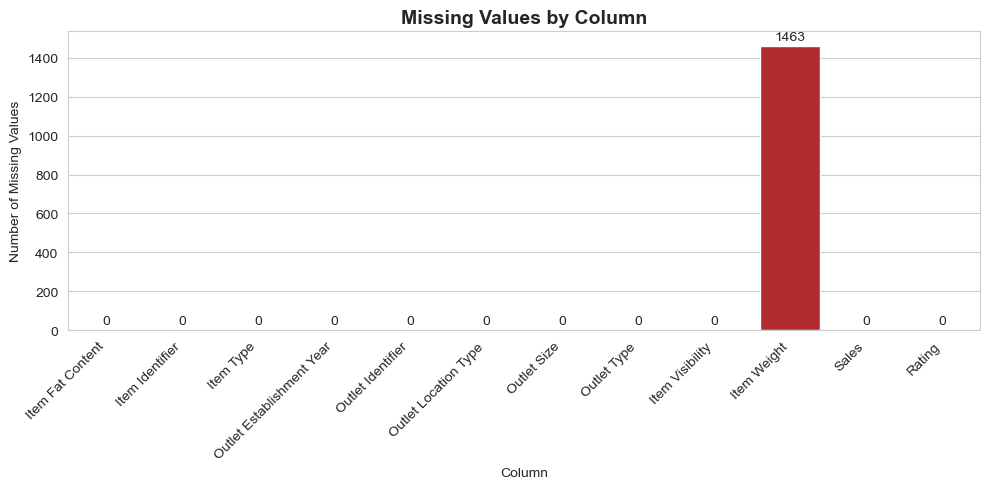

In [29]:
# Visualization 2.1: Missing values
plt.figure(figsize=(10, 5))
ax = sns.barplot(x=missing.index, y=missing["Missing_Count"], palette="Reds")
for c in ax.containers:
    ax.bar_label(c, padding=2)
plt.title("Missing Values by Column", fontsize=14, fontweight="bold")
plt.xlabel("Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**What this code does**

This is the cleaning step for missing values.

- **Item Weight:** the same product always has the same weight, so a missing weight is filled with the average weight of that product from its other rows (`groupby().transform("mean")`). A few products have no weight anywhere, so those get the median weight of their category.
- **Item Visibility:** the zeros are first turned into blanks with `replace(0, np.nan)` and then filled the same way, first with the product average and then with the category median.

The prints at the end confirm how many missing values are left.

In [30]:
# Fixing missing Item Weight
# Step 1: the same Item Identifier always has the same weight, so fill from other rows of that item
df_clean["Item Weight"] = df_clean["Item Weight"].fillna(
    df_clean.groupby("Item Identifier")["Item Weight"].transform("mean")
)
print("Weight still missing after Step 1:", df_clean["Item Weight"].isnull().sum())

# Step 2: for the few items that never have a weight, use the median of their Item Type
df_clean["Item Weight"] = df_clean["Item Weight"].fillna(
    df_clean.groupby("Item Type")["Item Weight"].transform("median")
)
print("Weight still missing after Step 2:", df_clean["Item Weight"].isnull().sum())

# Fixing Item Visibility = 0 (treated as wrong/missing)
vis = df_clean["Item Visibility"].replace(0, np.nan)
df_clean["Item Visibility"] = vis.fillna(
    vis.groupby(df_clean["Item Identifier"]).transform("mean")
)
df_clean["Item Visibility"] = df_clean["Item Visibility"].fillna(
    df_clean.groupby("Item Type")["Item Visibility"].transform("median")
)

print("Zero visibility left:", (df_clean["Item Visibility"] == 0).sum())
print("Total missing values left:", df_clean.isnull().sum().sum())

Weight still missing after Step 1: 4
Weight still missing after Step 2: 0
Zero visibility left: 0
Total missing values left: 0


### Task 2.2: Find information that has been repeated more than once

**What this code does**

I check for duplicates in two ways: rows that are exactly the same, and the same item appearing twice in the same outlet. `drop_duplicates()` is kept as a safety step. Since there are no duplicates, no rows are removed.

In [31]:
print("=" * 60)
print("TASK 2.2: DUPLICATE RECORDS")
print("=" * 60)

print("Fully duplicated rows              :", df.duplicated().sum())
print("Same Item sold in same Outlet twice:",
      df.duplicated(subset=["Item Identifier", "Outlet Identifier"]).sum())

# Remove duplicates if any exist (here there are none, so nothing changes)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print("Rows after duplicate check:", df_clean.shape[0])

TASK 2.2: DUPLICATE RECORDS
Fully duplicated rows              : 0
Same Item sold in same Outlet twice: 0
Rows after duplicate check: 8523


### Task 2.3: Find values that look unusually high or unusually low

**What this code does**

To find unusually high or low values I use the IQR method. Q1 is the 25% point and Q3 is the 75% point, and the IQR is the gap between them. A value below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR is counted as an outlier. The loop does this for Sales, Item Visibility, Item Weight and Rating and collects the limits and counts in one table.

In [32]:
print("=" * 60)
print("TASK 2.3: OUTLIER DETECTION (IQR METHOD)")
print("=" * 60)

num_cols = ["Sales", "Item Visibility", "Item Weight", "Rating"]
outlier_rows = []

for col in num_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    low_count = (df_clean[col] < lower).sum()
    high_count = (df_clean[col] > upper).sum()
    total = low_count + high_count
    outlier_rows.append([col, round(lower, 3), round(upper, 3),
                         low_count, high_count, total,
                         round(total / len(df_clean) * 100, 2)])

outlier_summary = pd.DataFrame(outlier_rows, columns=[
    "Column", "Lower_Limit", "Upper_Limit", "Unusually_Low",
    "Unusually_High", "Total_Outliers", "Outlier_%"])
outlier_summary

TASK 2.3: OUTLIER DETECTION (IQR METHOD)


,Column,Lower_Limit,Upper_Limit,Unusually_Low,Unusually_High,Total_Outliers,Outlier_%
0,Sales,-43.899,323.370,0,0,0,0.00
1,Item Visibility,-0.070,0.200,0,144,144,1.69
2,Item Weight,-3.313,28.948,0,0,0,0.00
3,Rating,3.700,4.500,1246,685,1931,22.66


**What this code does**

Boxplots of the four numeric columns. The dots outside the whiskers are the outliers found above.

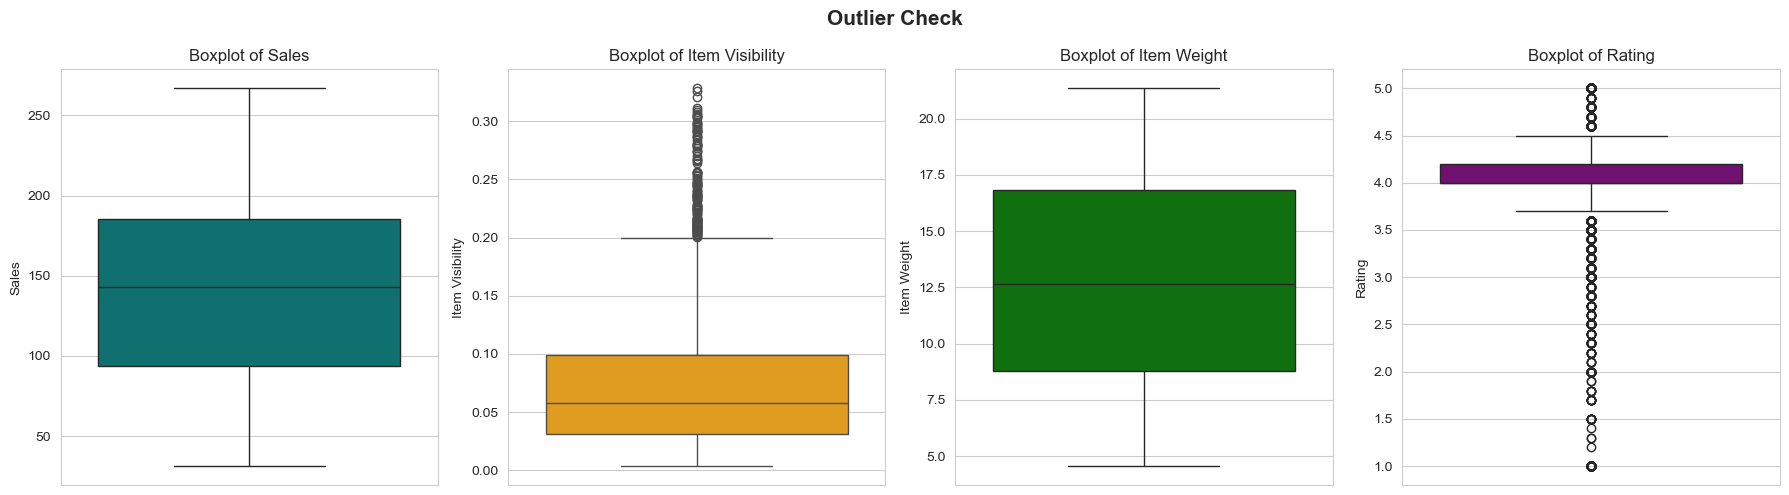

In [33]:
# Visualization 2.3: Boxplots to spot outliers
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
colors = ["teal", "orange", "green", "purple"]
for ax, col, color in zip(axes, num_cols, colors):
    sns.boxplot(y=df_clean[col], color=color, ax=ax)
    ax.set_title(f"Boxplot of {col}")
plt.suptitle("Outlier Check", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

### Task 2.4: Make sure similar information is presented in the same way

**What this code does**

`Item Fat Content` has the same two values written in five different ways (`Low Fat`, `low fat`, `LF`, `Regular`, `reg`). `replace()` changes them into just two labels. Items whose ID starts with `NC` are non-consumable products like household and hygiene items, so fat content does not apply to them and I mark them as `Non-Edible`. I assumed the `NC` prefix means non-consumable, which should be confirmed with the data source.

In [34]:
print("=" * 60)
print("TASK 2.4: STANDARDISING CATEGORIES")
print("=" * 60)

# A) Item Fat Content: 5 labels for what should be 2
print("Before:\n", df_clean["Item Fat Content"].value_counts(), "\n")

df_clean["Item Fat Content"] = df_clean["Item Fat Content"].replace({
    "LF": "Low Fat",
    "low fat": "Low Fat",
    "reg": "Regular"
})

# Item IDs starting with "NC" are non-consumables (household, hygiene), so fat content makes no sense
df_clean.loc[df_clean["Item Identifier"].str.startswith("NC"), "Item Fat Content"] = "Non-Edible"

print("After:\n", df_clean["Item Fat Content"].value_counts())

TASK 2.4: STANDARDISING CATEGORIES
Before:
 Item Fat Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64 

After:
 Item Fat Content
Low Fat       3918
Regular       3006
Non-Edible    1599
Name: count, dtype: int64


**What this code does**

Two bar charts to compare the fat content labels before cleaning (5 labels) and after cleaning (3 labels).

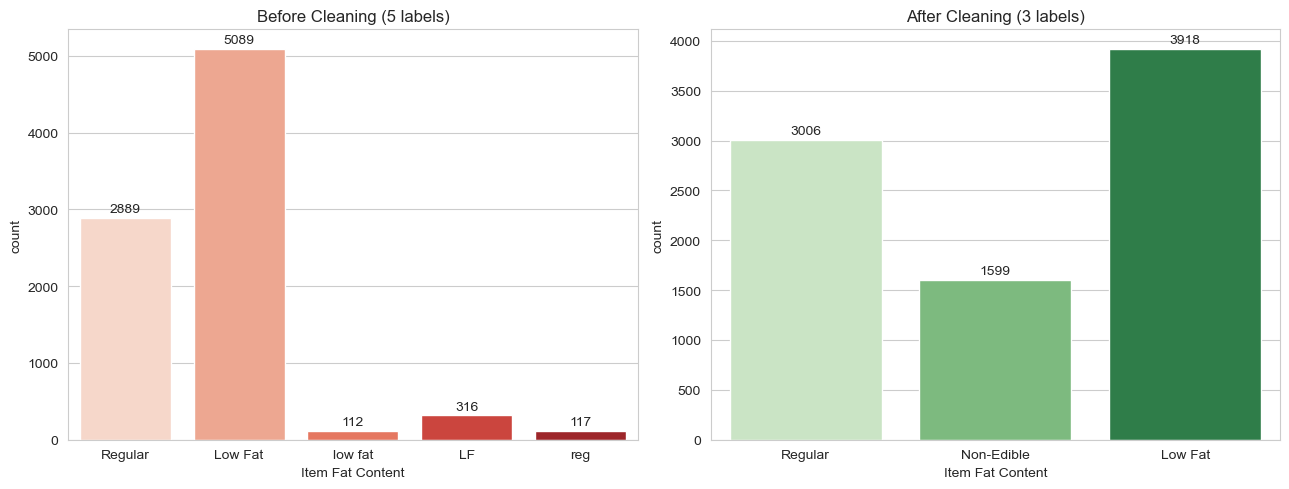

In [35]:
# Visualization 2.4a: Fat content before and after cleaning
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(x=df["Item Fat Content"], palette="Reds", ax=axes[0])
axes[0].set_title("Before Cleaning (5 labels)")

sns.countplot(x=df_clean["Item Fat Content"], palette="Greens", ax=axes[1])
axes[1].set_title("After Cleaning (3 labels)")

for ax in axes:
    for c in ax.containers:
        ax.bar_label(c, padding=2)
plt.tight_layout()
plt.show()

**What this code does**

Before fixing the outlet size I check the problem. `nunique()` counts how many different sizes each outlet has. An outlet should have only one, so any outlet with more than one is a problem. The table below shows how the rows of those outlets are split between High, Medium and Small.

In [25]:
# B) Outlet Size: each outlet should have only ONE size
size_check = df_clean.groupby("Outlet Identifier")["Outlet Size"].nunique()
print("Outlets with more than one size listed:")
print(size_check[size_check > 1], "\n")

pd.crosstab(df_clean["Outlet Identifier"], df_clean["Outlet Size"]).loc[size_check[size_check > 1].index]

Outlets with more than one size listed:
Outlet Identifier
OUT010    3
OUT017    3
OUT045    3
Name: Outlet Size, dtype: int64 



Outlet Size,High,Medium,Small
Outlet Identifier,,,
OUT010,233,265,57
OUT017,314,244,368
OUT045,274,329,326


**What this code does**

Fixing the outlet size. Each outlet should have only one size, so I take the most common size of each outlet with `mode()` and apply it to all rows of that outlet using `map()`. The prints confirm that every outlet now has exactly one size.

In [36]:
# Fix: give each outlet its most common size
mode_size = df_clean.groupby("Outlet Identifier")["Outlet Size"].agg(lambda x: x.mode()[0])
df_clean["Outlet Size"] = df_clean["Outlet Identifier"].map(mode_size)

print("Max sizes per outlet after fix:", df_clean.groupby("Outlet Identifier")["Outlet Size"].nunique().max())
print(df_clean.drop_duplicates("Outlet Identifier")["Outlet Size"].value_counts())

Max sizes per outlet after fix: 1
Outlet Size
Medium    5
Small     4
High      1
Name: count, dtype: int64


**What this code does**

A final check after all the cleaning: the shape of the data, the number of missing values, the number of duplicates and the fat content labels that are left.

In [37]:
# C) Final reliability check
print("Shape               :", df_clean.shape)
print("Missing values      :", df_clean.isnull().sum().sum())
print("Duplicate rows      :", df_clean.duplicated().sum())
print("Fat Content labels  :", df_clean["Item Fat Content"].unique())
df_clean.head()

Shape               : (8523, 12)
Missing values      : 0
Duplicate rows      : 0
Fat Content labels  : ['Regular' 'Non-Edible' 'Low Fat']


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Non-Edible,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Medium,Supermarket Type1,0.033970,19.60,55.1614,5.0


**What I found**

- Only **Item Weight** had missing values (1,463 rows, 17.2%). 526 rows also had an Item Visibility of 0. After the cleaning no missing values are left.
- There are no duplicate rows, and no item is repeated in the same outlet.
- Sales and Item Weight have no outliers. 144 high Item Visibility values and many Rating values were flagged, but I kept them because they look like real values. Rating is flagged a lot only because so many ratings are exactly 4.0 that the normal range becomes very narrow.
- Item Fat Content went from 5 labels to 3 (Low Fat, Regular, Non-Edible).
- Three outlets (OUT010, OUT017 and OUT045) had more than one size in the data. I gave each of them its most common size, which is an assumption that should be confirmed with the data source. After this the sizes are 5 Medium, 4 Small and 1 High.

## Objective 3: Find Out What Is Driving Better Sales Performance

### Task 3.1: Find out which types of products are selling more

**What this code does**

This shows which product categories sell the most. For each `Item Type` it calculates total sales, average sales per record, number of records and average rating. `Sales_Share_%` is the share of each category in the total sales. The print line adds up the share of the top 5 categories.

In [39]:
print("=" * 60)
print("TASK 3.1: PRODUCT TYPE PERFORMANCE")
print("=" * 60)

item_type_perf = (
    df_clean.groupby("Item Type")
    .agg(Total_Sales=("Sales", "sum"),
         Avg_Sales=("Sales", "mean"),
         Records=("Sales", "count"),
         Avg_Rating=("Rating", "mean"))
    .round(2)
    .sort_values("Total_Sales", ascending=False)
)
item_type_perf["Sales_Share_%"] = (item_type_perf["Total_Sales"] / item_type_perf["Total_Sales"].sum() * 100).round(2)

print("Top 5 categories together make up:", item_type_perf["Sales_Share_%"].head(5).sum().round(2), "% of all sales\n")
item_type_perf

TASK 3.1: PRODUCT TYPE PERFORMANCE
Top 5 categories together make up: 59.04 % of all sales



,Total_Sales,Avg_Sales,Records,Avg_Rating,Sales_Share_%
Item Type,,,,,
Fruits and Vegetables,178124.08,144.58,1232,3.96,14.82
Snack Foods,175433.92,146.19,1200,3.95,14.60
Household,135976.53,149.42,910,4.00,11.32
Frozen Foods,118558.88,138.50,856,3.97,9.87
Dairy,101276.46,148.50,682,3.97,8.43
Canned,90706.73,139.76,649,3.99,7.55
Baking Goods,81894.74,126.38,648,3.98,6.82
Health and Hygiene,68025.84,130.82,520,3.99,5.66
Meat,59449.86,139.88,425,4.02,4.95


**What this code does**

Two bar charts. The left one shows total sales by category and the right one shows the average sale per record. I show both because a category can have high total sales just because it has many records, not because each sale is bigger.

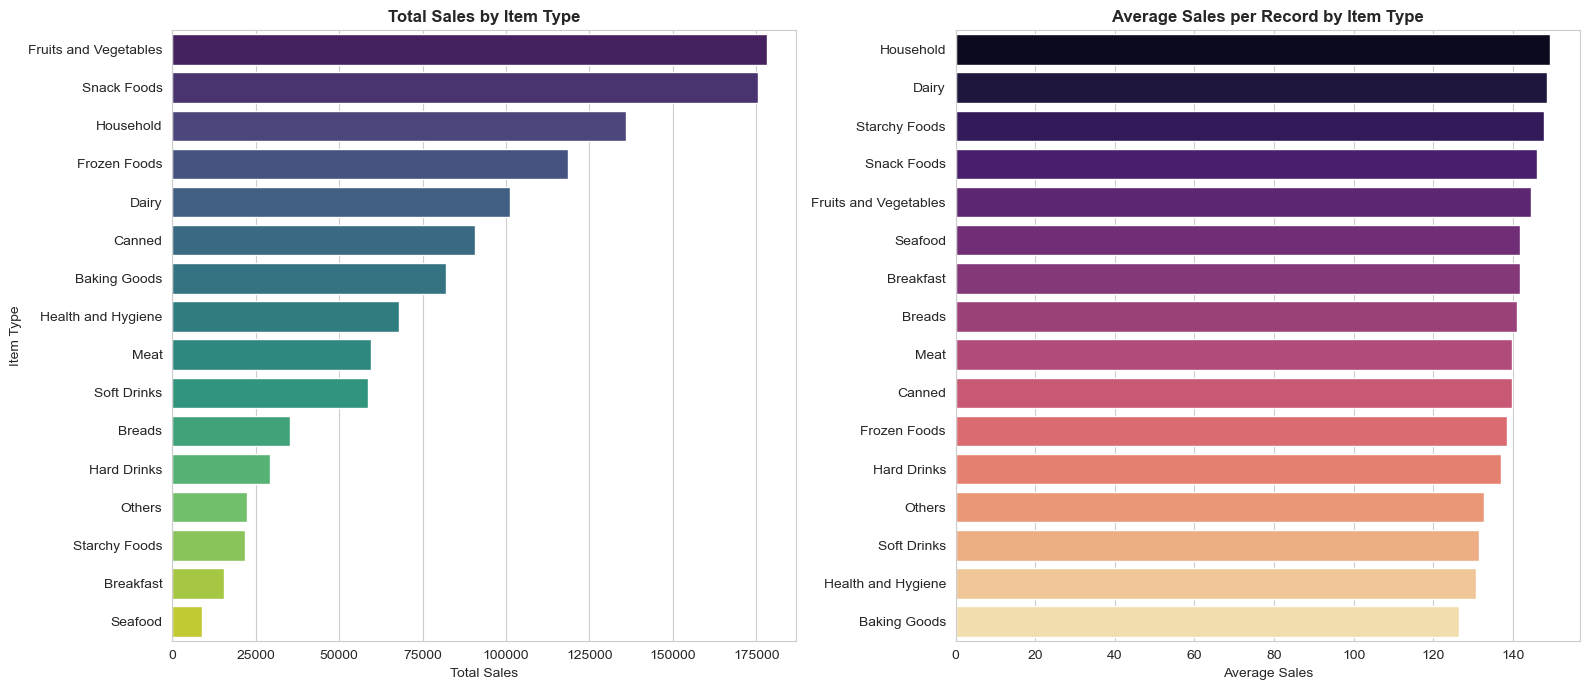

In [40]:
# Visualization 3.1a: Total sales vs average sales per record, by Item Type
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(x=item_type_perf["Total_Sales"], y=item_type_perf.index, palette="viridis", ax=axes[0])
axes[0].set_title("Total Sales by Item Type", fontweight="bold")
axes[0].set_xlabel("Total Sales")

avg_order = item_type_perf.sort_values("Avg_Sales", ascending=False)
sns.barplot(x=avg_order["Avg_Sales"], y=avg_order.index, palette="magma", ax=axes[1])
axes[1].set_title("Average Sales per Record by Item Type", fontweight="bold")
axes[1].set_xlabel("Average Sales")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**What this code does**

The same idea for fat content: do Low Fat, Regular and Non-Edible products sell differently? The table and the two charts compare total sales and average sales.

                  Total_Sales  Avg_Sales  Records
Item Fat Content                                 
Low Fat             549865.43     140.34     3918
Non-Edible          226454.26     141.62     1599
Regular             425361.80     141.50     3006


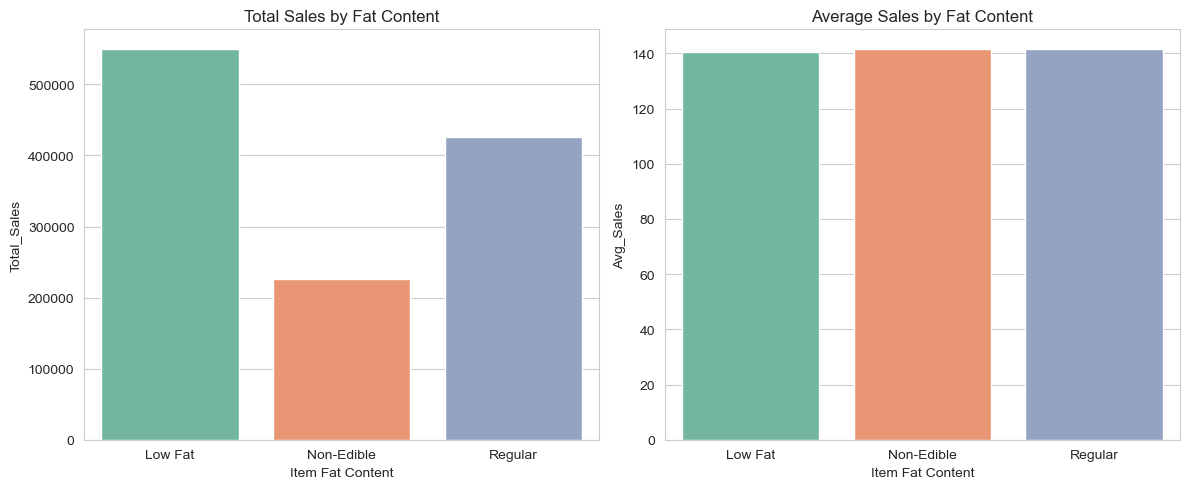

In [41]:
# Fat content: do Low Fat, Regular and Non-Edible products sell differently?
fat_perf = df_clean.groupby("Item Fat Content")["Sales"].agg(
    Total_Sales="sum", Avg_Sales="mean", Records="count").round(2)
print(fat_perf)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(x=fat_perf.index, y=fat_perf["Total_Sales"], palette="Set2", ax=axes[0])
axes[0].set_title("Total Sales by Fat Content")
sns.barplot(x=fat_perf.index, y=fat_perf["Avg_Sales"], palette="Set2", ax=axes[1])
axes[1].set_title("Average Sales by Fat Content")
plt.tight_layout()
plt.show()

**What this code does**

The top 10 individual products by total sales. I group by `Item Identifier`, add up the sales, sort from high to low and take the first 10 with `head(10)`.

  Item Identifier              Item Type      Sales
0           FDU12           Baking Goods  2371.0112
1           FDT07  Fruits and Vegetables  2306.8970
2           NCQ06              Household  2294.7126
3           FDL58            Snack Foods  2111.6544
4           NCB31              Household  2104.7280
5           FDX31  Fruits and Vegetables  2104.4622
6           FDF05           Frozen Foods  2103.1280
7           FDR59                 Breads  2096.5752
8           FDP28           Frozen Foods  2087.8488
9           FDA04           Frozen Foods  2072.0696


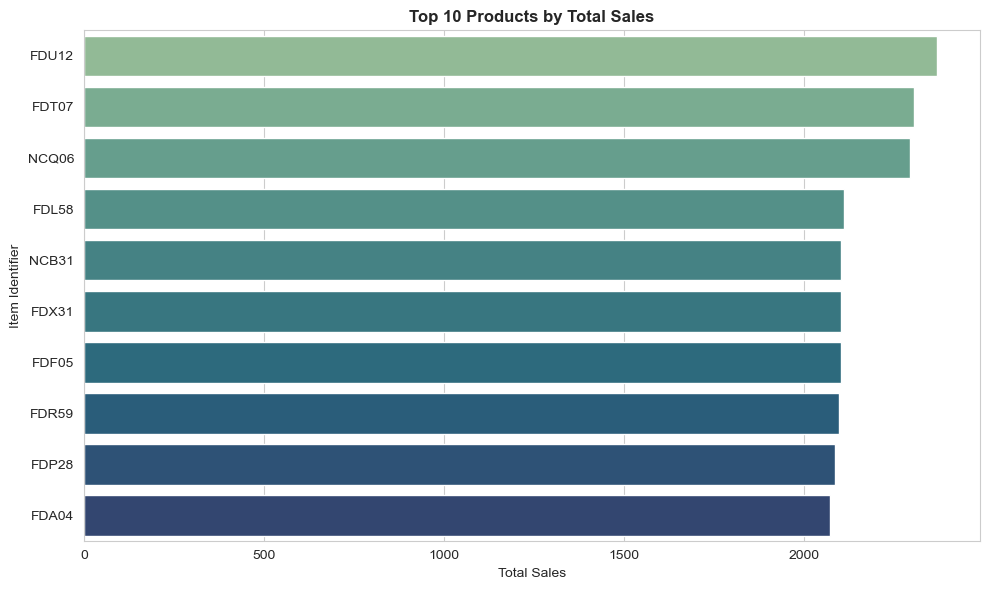

In [42]:
# Top 10 individual products by total sales
top10_products = (
    df_clean.groupby(["Item Identifier", "Item Type"])["Sales"].sum()
    .sort_values(ascending=False).head(10).reset_index()
)
print(top10_products)

plt.figure(figsize=(10, 6))
sns.barplot(data=top10_products, x="Sales", y="Item Identifier", palette="crest")
plt.title("Top 10 Products by Total Sales", fontweight="bold")
plt.xlabel("Total Sales")
plt.tight_layout()
plt.show()

**What I found**

- Fruits and Vegetables (178K) and Snack Foods (175K) sell the most. Together with Household, Frozen Foods and Dairy, the top 5 categories make up about 59% of all sales.
- Seafood, Breakfast and Starchy Foods sell the least.
- The average sale per record is similar in every category (about 126 to 149), so a category is at the top mostly because it has more records.
- Low Fat, Regular and Non-Edible products have almost the same average sale (about 140 to 142).

### Task 3.2: Find out which types of outlets are performing better

**What this code does**

This compares outlet type, outlet location and outlet size. The loop repeats the same steps for each of the three columns: total sales, average sale, number of records and number of outlets. Then `Avg_Sales_per_Outlet` divides the total by the number of outlets. This matters because Supermarket Type1 has 6 outlets and Type2 has only 1, so comparing plain totals would not be fair. The top row of charts shows the totals and the bottom row shows sales per outlet.

TASK 3.2: OUTLET PERFORMANCE

Performance by Outlet Type:
                   Total_Sales  Avg_Sales  Records  Outlets  \
Outlet Type                                                   
Grocery Store        151939.15     140.29     1083        2   
Supermarket Type1    787549.89     141.21     5577        6   
Supermarket Type2    131477.78     141.68      928        1   
Supermarket Type3    130714.67     139.80      935        1   

                   Avg_Sales_per_Outlet  
Outlet Type                              
Grocery Store                   75970.0  
Supermarket Type1              131258.0  
Supermarket Type2              131478.0  
Supermarket Type3              130715.0  

Performance by Outlet Location Type:
                      Total_Sales  Avg_Sales  Records  Outlets  \
Outlet Location Type                                             
Tier 1                  336397.81     140.87     2388        3   
Tier 2                  393150.65     141.17     2785        3   
Tier 3   

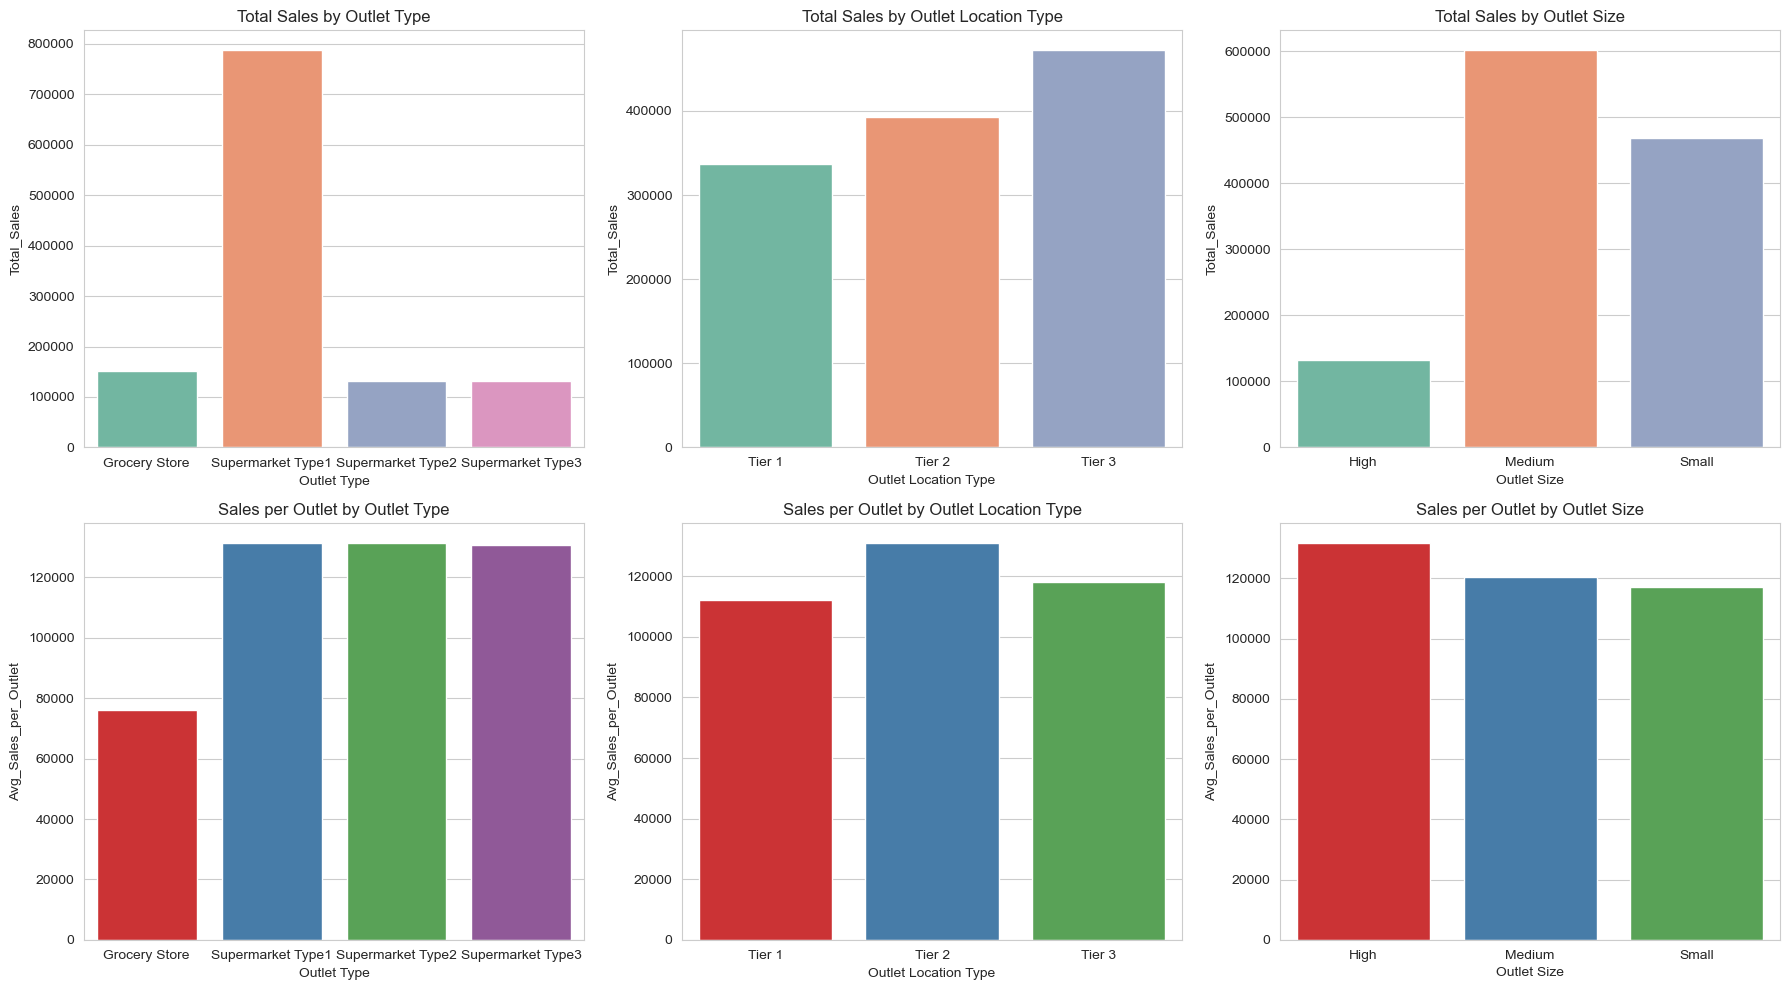

In [43]:
print("=" * 60)
print("TASK 3.2: OUTLET PERFORMANCE")
print("=" * 60)

outlet_cols = ["Outlet Type", "Outlet Location Type", "Outlet Size"]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for i, col in enumerate(outlet_cols):
    g = df_clean.groupby(col).agg(
        Total_Sales=("Sales", "sum"),
        Avg_Sales=("Sales", "mean"),
        Records=("Sales", "count"),
        Outlets=("Outlet Identifier", "nunique"))
    g["Avg_Sales_per_Outlet"] = (g["Total_Sales"] / g["Outlets"]).round(0)
    g = g.round(2)
    print(f"\nPerformance by {col}:")
    print(g)

    sns.barplot(x=g.index, y=g["Total_Sales"], palette="Set2", ax=axes[0, i])
    axes[0, i].set_title(f"Total Sales by {col}")
    sns.barplot(x=g.index, y=g["Avg_Sales_per_Outlet"], palette="Set1", ax=axes[1, i])
    axes[1, i].set_title(f"Sales per Outlet by {col}")

plt.tight_layout()
plt.show()

**What this code does**

The same kind of table for each individual outlet, sorted from the highest to the lowest total sales.

In [44]:
# Performance of each individual outlet
outlet_perf = (
    df_clean.groupby(["Outlet Identifier", "Outlet Type", "Outlet Location Type", "Outlet Size"])
    .agg(Total_Sales=("Sales", "sum"),
         Avg_Sales=("Sales", "mean"),
         Records=("Sales", "count"))
    .round(2)
    .sort_values("Total_Sales", ascending=False)
    .reset_index()
)
outlet_perf

,Outlet Identifier,Outlet Type,Outlet Location Type,Outlet Size,Total_Sales,Avg_Sales,Records
0,OUT035,Supermarket Type1,Tier 2,Small,133103.91,143.12,930
1,OUT046,Supermarket Type1,Tier 1,Small,132113.37,142.06,930
2,OUT013,Supermarket Type1,Tier 3,High,131809.02,141.43,932
3,OUT018,Supermarket Type2,Tier 3,Medium,131477.78,141.68,928
4,OUT045,Supermarket Type1,Tier 2,Medium,130942.78,140.95,929
5,OUT027,Supermarket Type3,Tier 3,Medium,130714.67,139.80,935
6,OUT049,Supermarket Type1,Tier 1,Medium,130476.86,140.30,930
7,OUT017,Supermarket Type1,Tier 2,Small,129103.96,139.42,926
8,OUT010,Grocery Store,Tier 3,Medium,78131.57,140.78,555
9,OUT019,Grocery Store,Tier 1,Small,73807.58,139.79,528


**What this code does**

A bar chart of the table above. The colour of each bar shows the outlet type.

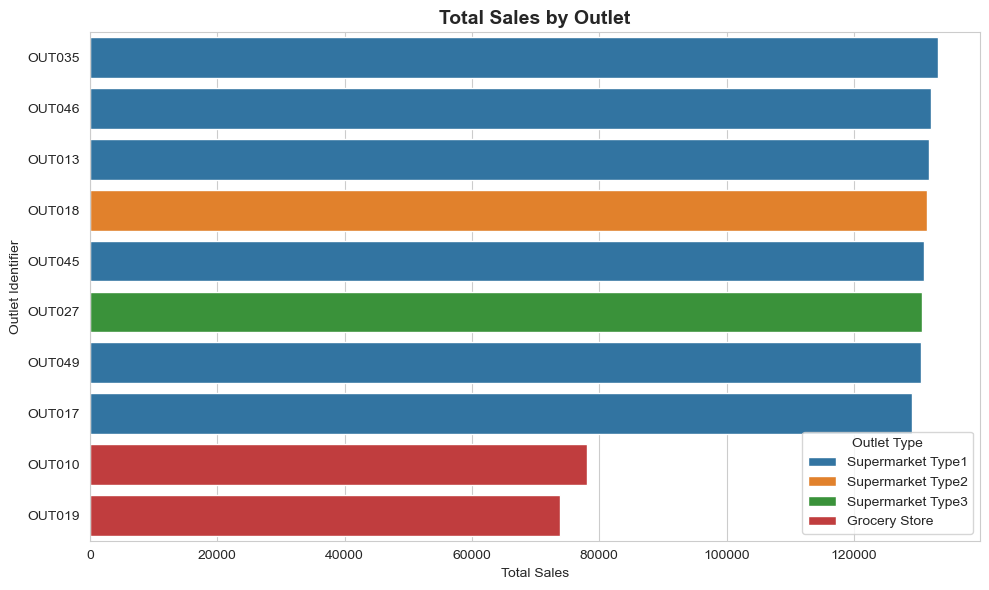

In [45]:
plt.figure(figsize=(10, 6))
sns.barplot(data=outlet_perf, x="Total_Sales", y="Outlet Identifier",
            hue="Outlet Type", dodge=False)
plt.title("Total Sales by Outlet", fontsize=14, fontweight="bold")
plt.xlabel("Total Sales")
plt.tight_layout()
plt.show()

**What I found**

- Grocery Stores are the weakest, with about 76K per outlet against about 131K for each supermarket type.
- Supermarket Type1, Type2 and Type3 are almost the same per outlet, so the supermarket type makes little difference.
- Tier 3 has the highest total only because it has 4 outlets. Per outlet, Tier 2 is the highest.
- OUT035, OUT046 and OUT013 are the top outlets. OUT010 and OUT019, the two Grocery Stores, are the lowest.

### Task 3.3: Understand whether visibility, weight, ratings and outlet characteristics are connected with sales

**What this code does**

To see if anything is connected with sales I calculate the correlation. It is a number between -1 and +1. Near 0 means no link, near +1 means both rise together and near -1 means one goes up while the other goes down.

In [46]:
print("=" * 60)
print("TASK 3.3: WHAT IS CONNECTED WITH SALES?")
print("=" * 60)

num_cols = ["Sales", "Item Visibility", "Item Weight", "Rating", "Outlet Establishment Year"]
corr = df_clean[num_cols].corr().round(3)
corr

TASK 3.3: WHAT IS CONNECTED WITH SALES?


,Sales,Item Visibility,Item Weight,Rating,Outlet Establishment Year
Sales,1.000,-0.006,0.026,0.011,-0.001
Item Visibility,-0.006,1.000,-0.021,-0.004,-0.058
Item Weight,0.026,-0.021,1.000,0.004,-0.002
Rating,0.011,-0.004,0.004,1.000,0.000
Outlet Establishment Year,-0.001,-0.058,-0.002,0.000,1.000


**What this code does**

The correlation table drawn as a coloured heatmap with the numbers written in each box.

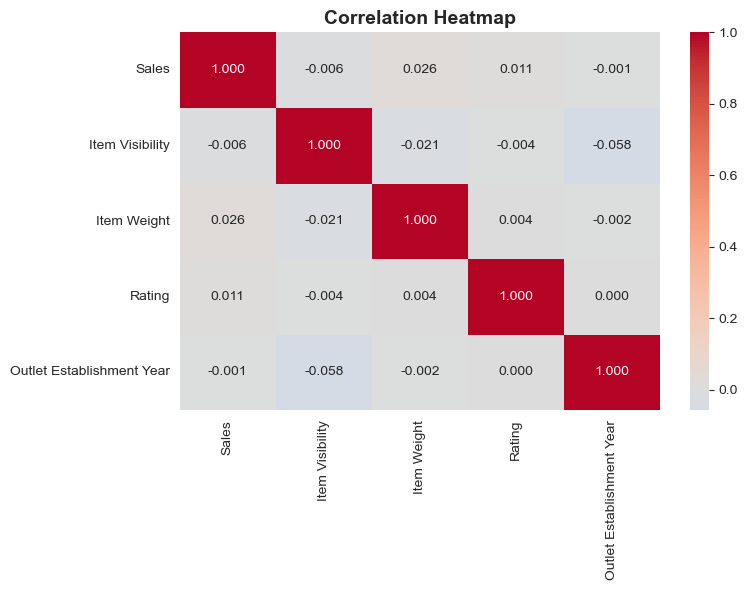

In [47]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".3f")
plt.title("Correlation Heatmap", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**What this code does**

Scatter plots of sales against visibility, weight and rating. Each dot is one record. If there was a link, the dots would follow a line or a shape.

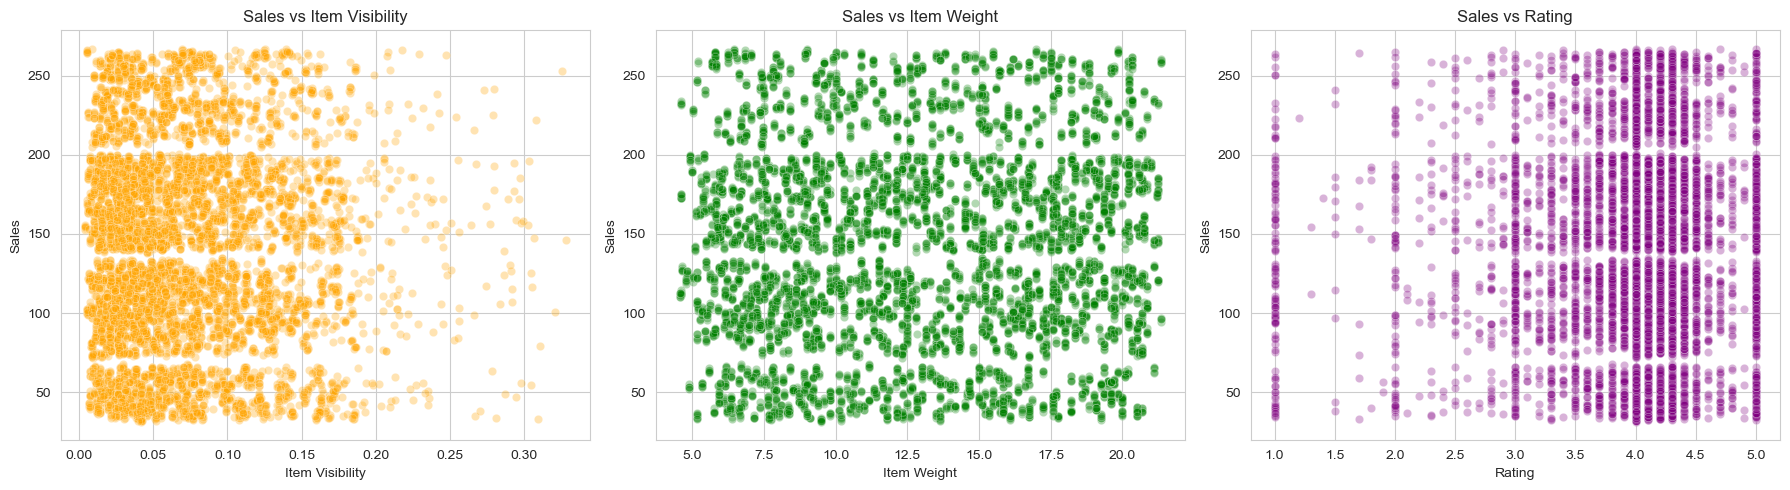

In [48]:
# Scatter plots: Sales against each numeric factor
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col, color in zip(axes, ["Item Visibility", "Item Weight", "Rating"],
                          ["orange", "green", "purple"]):
    sns.scatterplot(data=df_clean, x=col, y="Sales", alpha=0.3, color=color, ax=ax)
    ax.set_title(f"Sales vs {col}")
plt.tight_layout()
plt.show()

**What this code does**

Here I split the numbers into groups and compare the average sales of each group. `pd.qcut` splits visibility into 4 equal-sized groups and `pd.cut` splits the rating into the bands I chose (below 3, 3 to 3.9, exactly 4, above 4).

In [49]:
# Group the numbers into bands and compare average sales
df_clean["Visibility_Group"] = pd.qcut(df_clean["Item Visibility"], 4,
                                       labels=["Low", "Medium-Low", "Medium-High", "High"])
df_clean["Rating_Group"] = pd.cut(df_clean["Rating"], bins=[0, 3, 3.99, 4.0, 5],
                                  labels=["Below 3", "3 to 3.9", "Exactly 4", "Above 4"])

print("Average sales by Visibility group:")
print(df_clean.groupby("Visibility_Group")["Sales"].mean().round(2), "\n")
print("Average sales by Rating group:")
print(df_clean.groupby("Rating_Group")["Sales"].agg(["mean", "count"]).round(2))

Average sales by Visibility group:
Visibility_Group
Low            141.04
Medium-Low     137.16
Medium-High    148.39
High           137.38
Name: Sales, dtype: float64 

Average sales by Rating group:
                mean  count
Rating_Group               
Below 3       138.99    617
3 to 3.9      140.76   1395
Exactly 4     142.48   3339
Above 4       139.92   3172


**What this code does**

Boxplots of sales for each group (outlet type, location, size, fat content, visibility group and rating group). They show the typical range of sales inside every group.

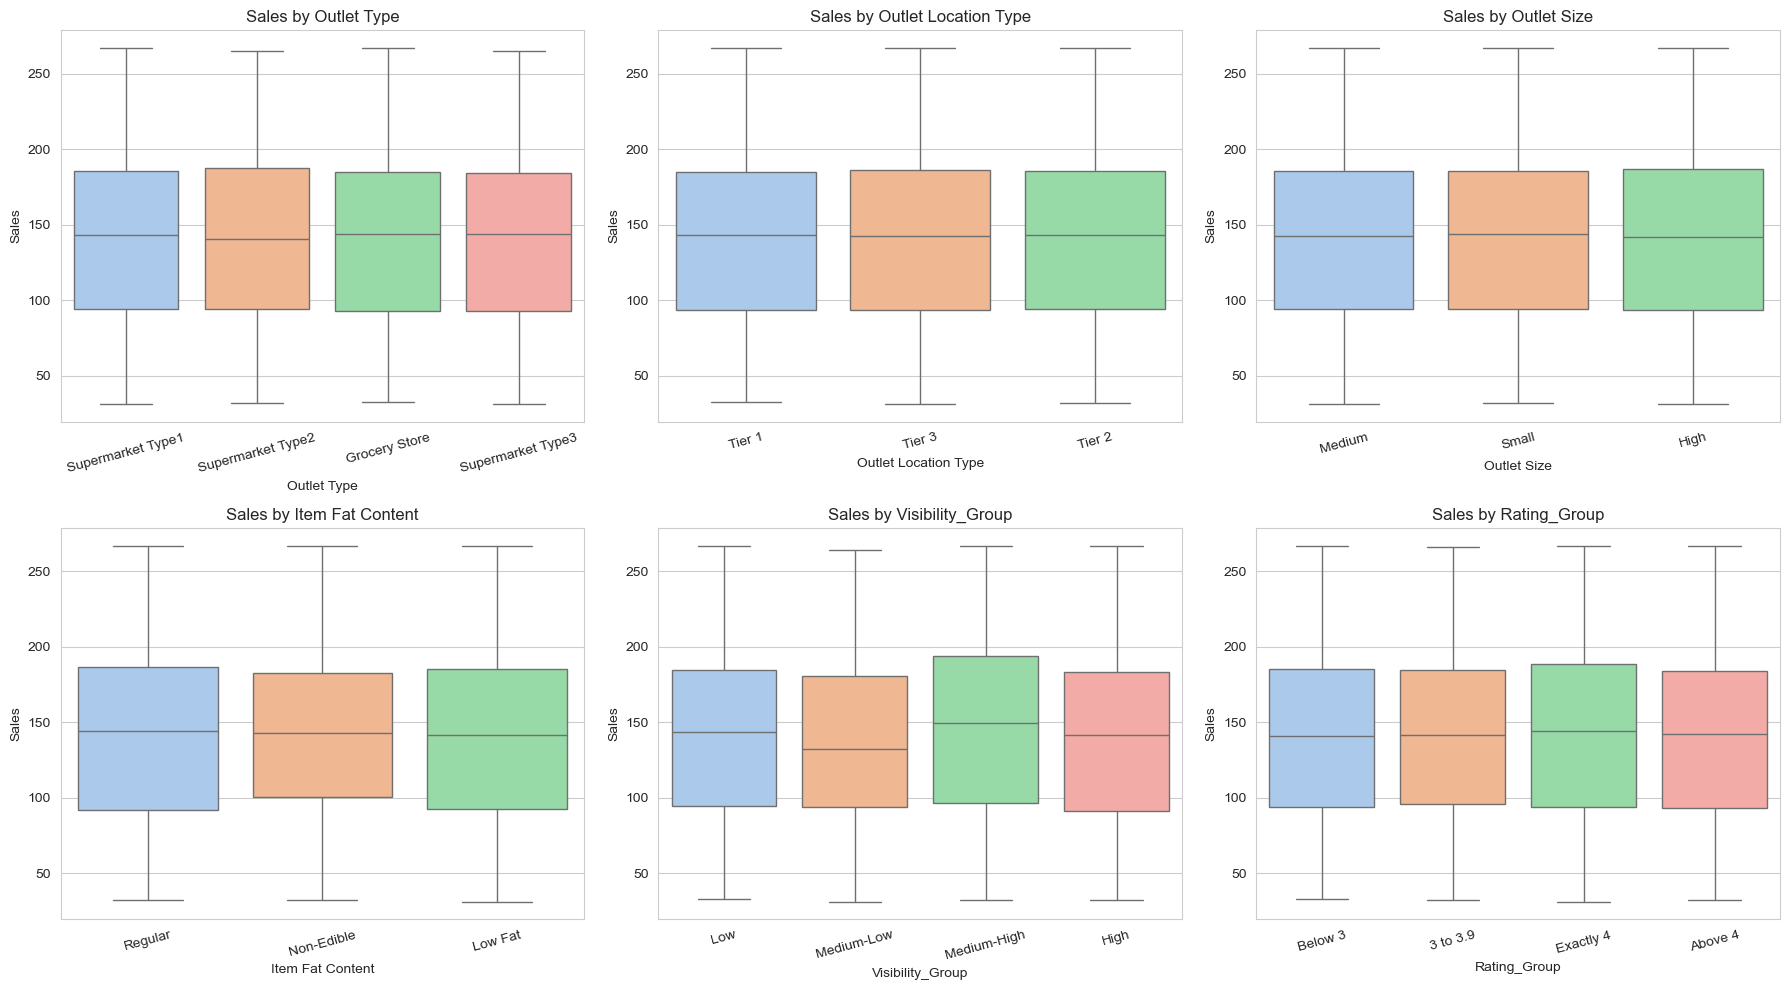

In [50]:
# Boxplots: how Sales spreads across each group
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
group_cols = ["Outlet Type", "Outlet Location Type", "Outlet Size",
              "Item Fat Content", "Visibility_Group", "Rating_Group"]
for ax, col in zip(axes.flatten(), group_cols):
    sns.boxplot(data=df_clean, x=col, y="Sales", palette="pastel", ax=ax)
    ax.set_title(f"Sales by {col}")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

**What I found**

- Every correlation with Sales is almost zero: Visibility -0.006, Weight 0.026, Rating 0.011 and Establishment Year -0.001. In this data none of these factors predicts sales.
- The scatter plots look like random clouds and the visibility groups show no clear trend (average sales between 137 and 148).
- The average sale per record is about 141 whatever the outlet or product group, so the differences in total sales come from the number of records, not from the size of each sale.

### Task 3.4: Compare better-performing and lower-performing products and outlets

**What this code does**

This compares the better selling products with the weaker ones. First I make a table with one row per product (total sales, visibility, weight, rating and the number of outlets that sell it). `quantile(0.75)` and `quantile(0.25)` give the cut-off values, so the top 25% and the bottom 25% of products by total sales can be separated. Then I compare the average of each factor for the two groups.

In [52]:
print("=" * 60)
print("TASK 3.4: TOP vs BOTTOM PERFORMERS")
print("=" * 60)

# One row per product
item_summary = (
    df_clean.groupby("Item Identifier")
    .agg(Item_Type=("Item Type", "first"),
         Total_Sales=("Sales", "sum"),
         Avg_Visibility=("Item Visibility", "mean"),
         Avg_Weight=("Item Weight", "mean"),
         Avg_Rating=("Rating", "mean"),
         Outlets_Selling=("Outlet Identifier", "nunique"))
    .reset_index()
)

# Top 25% and bottom 25% products by total sales
top_cut = item_summary["Total_Sales"].quantile(0.75)
low_cut = item_summary["Total_Sales"].quantile(0.25)
top_products = item_summary[item_summary["Total_Sales"] >= top_cut]
low_products = item_summary[item_summary["Total_Sales"] <= low_cut]

compare_cols = ["Total_Sales", "Avg_Visibility", "Avg_Weight", "Avg_Rating", "Outlets_Selling"]
product_compare = pd.DataFrame({
    "Top 25% Products": top_products[compare_cols].mean(),
    "Bottom 25% Products": low_products[compare_cols].mean()
}).round(3)
product_compare

TASK 3.4: TOP vs BOTTOM PERFORMERS


,Top 25% Products,Bottom 25% Products
Total_Sales,1344.455,296.496
Avg_Visibility,0.073,0.070
Avg_Weight,13.072,12.331
Avg_Rating,3.962,3.964
Outlets_Selling,6.567,4.659


**What this code does**

Bar charts to compare the top 25% and the bottom 25% products on the number of outlets selling them, visibility and rating.

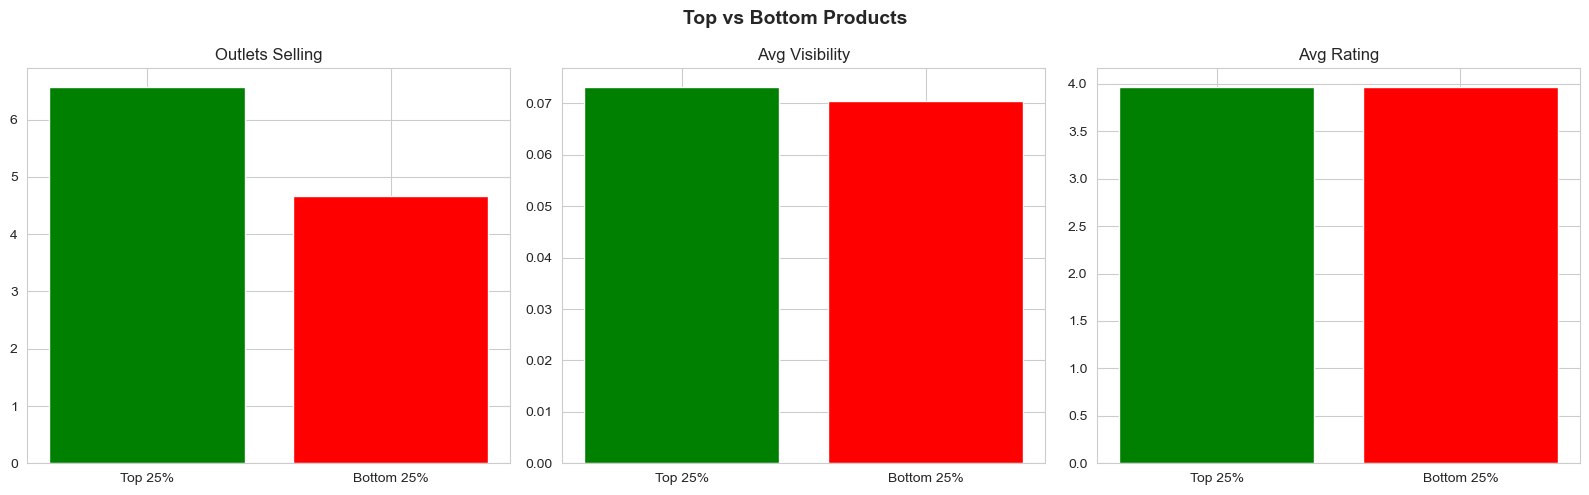

In [53]:
# Visualization 3.4a: Top vs bottom products
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ["Outlets_Selling", "Avg_Visibility", "Avg_Rating"]):
    ax.bar(["Top 25%", "Bottom 25%"],
           [top_products[col].mean(), low_products[col].mean()],
           color=["green", "red"])
    ax.set_title(col.replace("_", " "))
plt.suptitle("Top vs Bottom Products", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**What this code does**

Which categories are inside each group? `value_counts()` shows the 5 most common categories among the top products and among the bottom products.

In [54]:
# Which categories are in each group?
print("Top 25% products - most common Item Types:")
print(top_products["Item_Type"].value_counts().head(5), "\n")
print("Bottom 25% products - most common Item Types:")
print(low_products["Item_Type"].value_counts().head(5))

Top 25% products - most common Item Types:
Item_Type
Snack Foods              56
Fruits and Vegetables    56
Household                44
Dairy                    40
Frozen Foods             39
Name: count, dtype: int64 

Bottom 25% products - most common Item Types:
Item_Type
Frozen Foods             47
Fruits and Vegetables    46
Snack Foods              45
Dairy                    36
Baking Goods             35
Name: count, dtype: int64


**What this code does**

The 3 best and the 3 worst outlets by total sales, using `head(3)` and `tail(3)` on the outlet table made earlier.

In [55]:
# Best 3 vs worst 3 outlets
best3 = outlet_perf.head(3)
worst3 = outlet_perf.tail(3)
cols = ["Outlet Identifier", "Outlet Type", "Outlet Location Type", "Outlet Size",
        "Total_Sales", "Records", "Avg_Sales"]
print("BEST 3 OUTLETS:")
print(best3[cols], "\n")
print("WORST 3 OUTLETS:")
print(worst3[cols])

BEST 3 OUTLETS:
  Outlet Identifier        Outlet Type Outlet Location Type Outlet Size  \
0            OUT035  Supermarket Type1               Tier 2       Small   
1            OUT046  Supermarket Type1               Tier 1       Small   
2            OUT013  Supermarket Type1               Tier 3        High   

   Total_Sales  Records  Avg_Sales  
0    133103.91      930     143.12  
1    132113.37      930     142.06  
2    131809.02      932     141.43   

WORST 3 OUTLETS:
  Outlet Identifier        Outlet Type Outlet Location Type Outlet Size  \
7            OUT017  Supermarket Type1               Tier 2       Small   
8            OUT010      Grocery Store               Tier 3      Medium   
9            OUT019      Grocery Store               Tier 1       Small   

   Total_Sales  Records  Avg_Sales  
7    129103.96      926     139.42  
8     78131.57      555     140.78  
9     73807.58      528     139.79  


**What I found**

- Top products are sold in about 6.6 outlets on average, against 4.7 for the bottom products. This is the biggest difference between the two groups.
- Visibility (0.073 vs 0.070) and rating (3.96 vs 3.96) are practically the same in both groups, so they do not explain the gap.
- The same categories (Fruits and Vegetables, Snack Foods, Frozen Foods, Dairy) appear in both groups, simply because they have the most products.
- The worst outlets are mostly the two Grocery Stores. Their average sale (about 140) is the same as in the best outlets, but they have only about 530 to 555 records against about 930. They sell the same value per sale, just fewer items.

**Overall takeaway for Objective 3:** sales seem to depend on how many products an outlet carries and in how many outlets a product is stocked. Visibility, weight, rating and supermarket type showed almost no link with sales.

## Objective 4: Help Management Make Better Business Decisions

### Task 4.1: Identify the products that are contributing more to sales

**What this code does**

Here I find which product categories contribute the most to sales. The table has each category's share and a running total (`Cumulative_%`). Based on that, each category gets a class: A (core) for the first 70% of sales, B (medium) for the next 20% and C (low) for the last 10%. This is called a Pareto or ABC analysis.

In [56]:
print("=" * 60)
print("TASK 4.1: PRODUCTS CONTRIBUTING MOST TO SALES")
print("=" * 60)

type_sales = (
    df_clean.groupby("Item Type")["Sales"].sum()
    .sort_values(ascending=False).reset_index()
)
type_sales["Share_%"] = (type_sales["Sales"] / type_sales["Sales"].sum() * 100).round(2)

cum = type_sales["Sales"].cumsum() / type_sales["Sales"].sum() * 100
type_sales["Cumulative_%"] = cum.round(2)
type_sales["Class"] = pd.cut(cum, bins=[0, 70, 90, 100.001],
                             labels=["A (core)", "B (medium)", "C (low)"])
type_sales

TASK 4.1: PRODUCTS CONTRIBUTING MOST TO SALES


,Item Type,Sales,Share_%,Cumulative_%,Class
0,Fruits and Vegetables,178124.0810,14.82,14.82,A (core)
1,Snack Foods,175433.9224,14.60,29.42,A (core)
2,Household,135976.5254,11.32,40.74,A (core)
3,Frozen Foods,118558.8814,9.87,50.60,A (core)
4,Dairy,101276.4616,8.43,59.03,A (core)
5,Canned,90706.7290,7.55,66.58,A (core)
6,Baking Goods,81894.7364,6.82,73.39,B (medium)
7,Health and Hygiene,68025.8388,5.66,79.06,B (medium)
8,Meat,59449.8638,4.95,84.00,B (medium)
9,Soft Drinks,58514.1670,4.87,88.87,B (medium)


**What this code does**

The Pareto chart. The bars are the sales of each category and the red line is the running total in percent. The dotted line marks 80%.

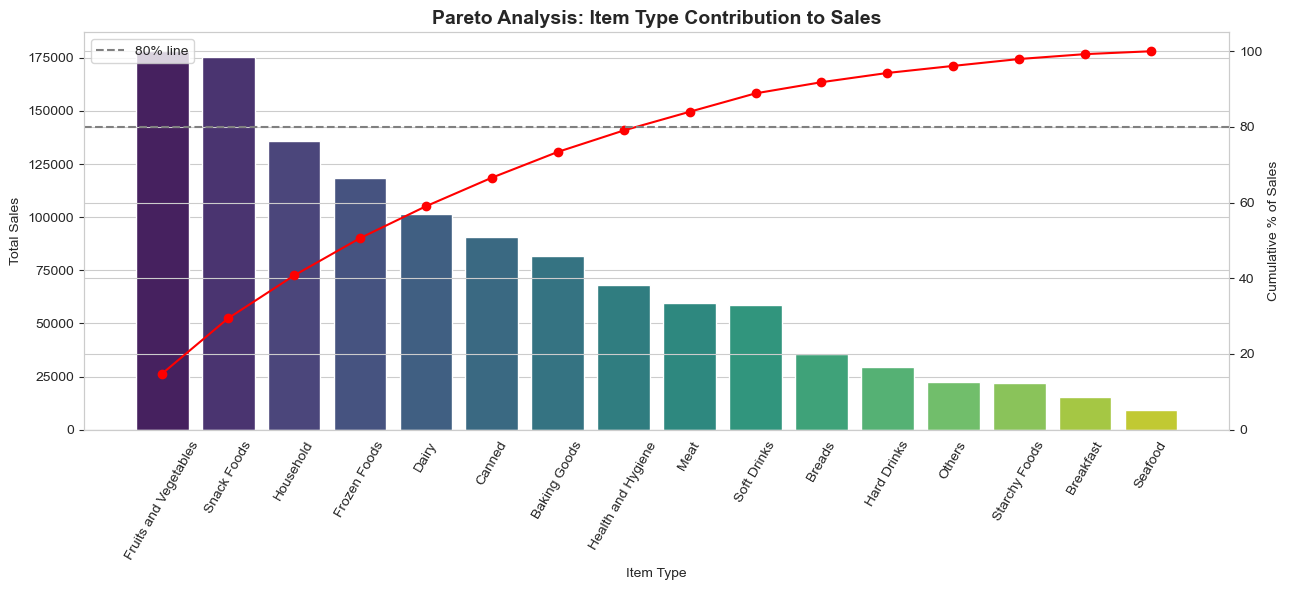

In [57]:
# Visualization 4.1a: Pareto chart (bars = sales, red line = cumulative %)
fig, ax1 = plt.subplots(figsize=(13, 6))
sns.barplot(data=type_sales, x="Item Type", y="Sales", palette="viridis", ax=ax1)
ax1.set_ylabel("Total Sales")
ax1.tick_params(axis="x", rotation=60)

ax2 = ax1.twinx()
ax2.plot(range(len(type_sales)), type_sales["Cumulative_%"], color="red", marker="o")
ax2.axhline(80, color="gray", linestyle="--", label="80% line")
ax2.set_ylabel("Cumulative % of Sales")
ax2.set_ylim(0, 105)
ax2.legend()

plt.title("Pareto Analysis: Item Type Contribution to Sales", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**What this code does**

The same question at the single product level. It finds how many products are needed to reach 80% of total sales, and how much the top 10 and the top 100 products contribute.

In [58]:
# How concentrated are sales at individual product level?
product_sales = df_clean.groupby("Item Identifier")["Sales"].sum().sort_values(ascending=False)
product_cum = product_sales.cumsum() / product_sales.sum() * 100
products_for_80 = (product_cum < 80).sum() + 1

print("Total unique products               :", len(product_sales))
print("Products needed to reach 80% of sales:", products_for_80,
      f"({products_for_80 / len(product_sales) * 100:.1f}% of products)")
print("Top 10 products share of sales      :", round(product_sales.head(10).sum() / product_sales.sum() * 100, 2), "%")
print("Top 100 products share of sales     :", round(product_sales.head(100).sum() / product_sales.sum() * 100, 2), "%")

Total unique products               : 1559
Products needed to reach 80% of sales: 931 (59.7% of products)
Top 10 products share of sales      : 1.8 %
Top 100 products share of sales     : 14.24 %


**What I found**

- The 6 Class A categories are Fruits and Vegetables, Snack Foods, Household, Frozen Foods, Dairy and Canned. Together they make up about 67% of sales.
- Fruits and Vegetables (14.8%) and Snack Foods (14.6%) lead.
- At single product level the sales are spread out. About 931 of the 1,559 products (around 60%) are needed to reach 80% of sales, and the top 10 products make only about 1.8%. So BlinkIT does not depend on a few star products.

### Task 4.2: Identify the outlets and locations that are performing better

**What this code does**

A table of every outlet with its total sales, number of records, average sale and its share of the total sales in percent.

In [59]:
print("=" * 60)
print("TASK 4.2: BEST OUTLETS AND LOCATIONS")
print("=" * 60)

outlet_sales = (
    df_clean.groupby(["Outlet Identifier", "Outlet Type", "Outlet Location Type"])
    .agg(Total_Sales=("Sales", "sum"),
         Records=("Sales", "count"),
         Avg_Sales=("Sales", "mean"))
    .reset_index()
    .sort_values("Total_Sales", ascending=False)
)
outlet_sales["Share_%"] = (outlet_sales["Total_Sales"] / outlet_sales["Total_Sales"].sum() * 100).round(2)
outlet_sales.round(2)

TASK 4.2: BEST OUTLETS AND LOCATIONS


,Outlet Identifier,Outlet Type,Outlet Location Type,Total_Sales,Records,Avg_Sales,Share_%
6,OUT035,Supermarket Type1,Tier 2,133103.91,930,143.12,11.08
8,OUT046,Supermarket Type1,Tier 1,132113.37,930,142.06,10.99
1,OUT013,Supermarket Type1,Tier 3,131809.02,932,141.43,10.97
3,OUT018,Supermarket Type2,Tier 3,131477.78,928,141.68,10.94
7,OUT045,Supermarket Type1,Tier 2,130942.78,929,140.95,10.90
5,OUT027,Supermarket Type3,Tier 3,130714.67,935,139.80,10.88
9,OUT049,Supermarket Type1,Tier 1,130476.86,930,140.30,10.86
2,OUT017,Supermarket Type1,Tier 2,129103.96,926,139.42,10.74
0,OUT010,Grocery Store,Tier 3,78131.57,555,140.78,6.50
4,OUT019,Grocery Store,Tier 1,73807.58,528,139.79,6.14


**What this code does**

A bar chart that ranks the outlets by total sales. The colours show the outlet type.

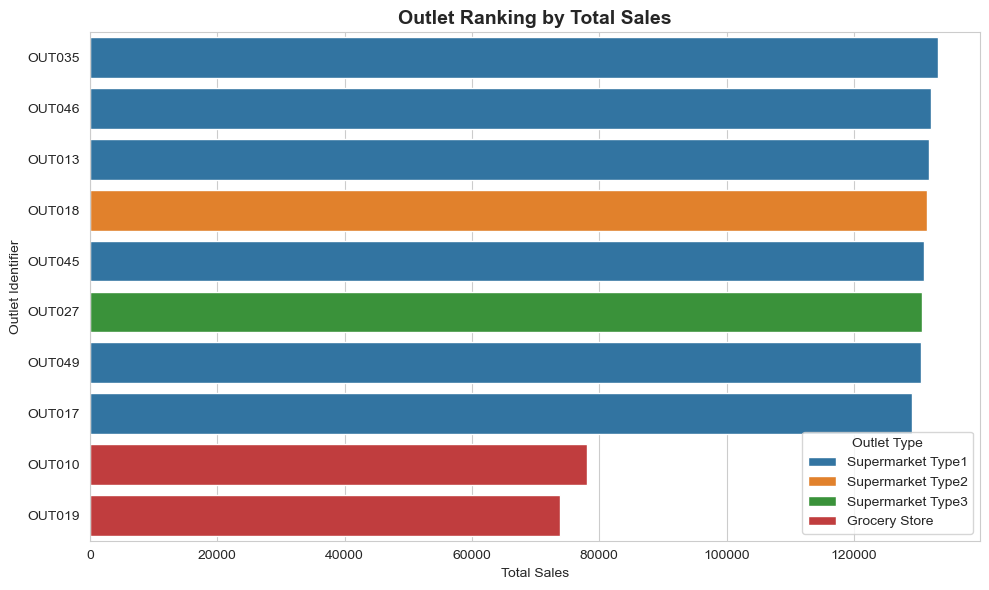

In [60]:
plt.figure(figsize=(10, 6))
sns.barplot(data=outlet_sales, x="Total_Sales", y="Outlet Identifier",
            hue="Outlet Type", dodge=False)
plt.title("Outlet Ranking by Total Sales", fontsize=14, fontweight="bold")
plt.xlabel("Total Sales")
plt.tight_layout()
plt.show()

**What this code does**

Performance by location (Tier 1, 2 and 3). The table shows total sales, number of outlets, sales per outlet and share of sales. The pie chart shows each tier's share and the bar chart shows sales per outlet, which is the fairer comparison.

                      Total_Sales  Outlets  Sales_per_Outlet  Share_%
Outlet Location Type                                                 
Tier 1                336397.8120        3          112133.0    27.99
Tier 2                393150.6476        3          131050.0    32.72
Tier 3                472133.0332        4          118033.0    39.29


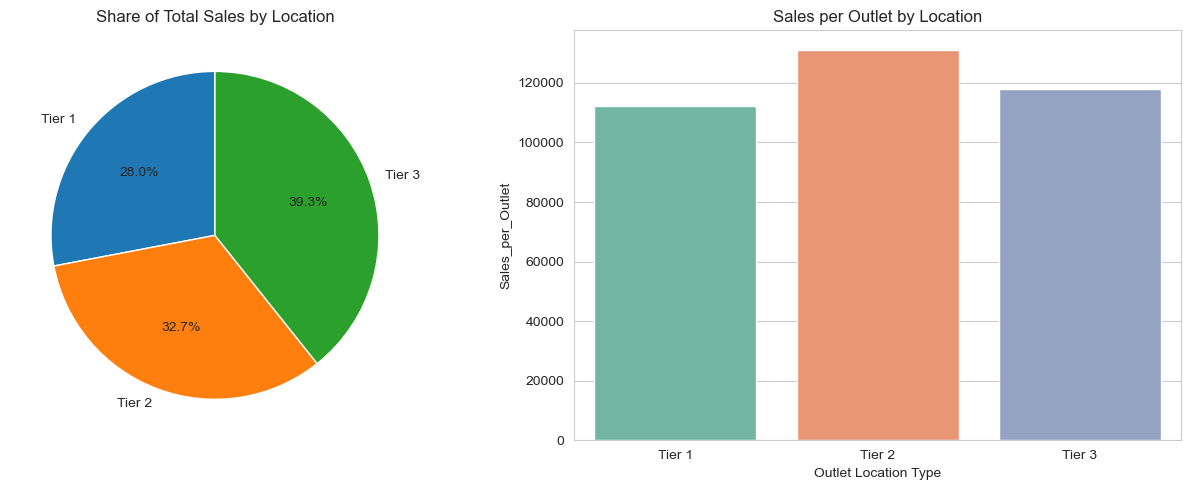

In [61]:
# Location performance
location_perf = (
    df_clean.groupby("Outlet Location Type")
    .agg(Total_Sales=("Sales", "sum"), Outlets=("Outlet Identifier", "nunique"))
)
location_perf["Sales_per_Outlet"] = (location_perf["Total_Sales"] / location_perf["Outlets"]).round(0)
location_perf["Share_%"] = (location_perf["Total_Sales"] / location_perf["Total_Sales"].sum() * 100).round(2)
print(location_perf)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].pie(location_perf["Total_Sales"], labels=location_perf.index,
            autopct="%1.1f%%", startangle=90)
axes[0].set_title("Share of Total Sales by Location")

sns.barplot(x=location_perf.index, y=location_perf["Sales_per_Outlet"], palette="Set2", ax=axes[1])
axes[1].set_title("Sales per Outlet by Location")
plt.tight_layout()
plt.show()

**What this code does**

`pivot_table` makes a grid of Location against Outlet Type with the total sales in each box. The heatmap shows it with colours. Empty boxes mean that combination does not exist in the data.

Outlet Type           Grocery Store  Supermarket Type1  Supermarket Type2  \
Outlet Location Type                                                        
Tier 1                      73808.0           262590.0                NaN   
Tier 2                          NaN           393151.0                NaN   
Tier 3                      78132.0           131809.0           131478.0   

Outlet Type           Supermarket Type3  
Outlet Location Type                     
Tier 1                              NaN  
Tier 2                              NaN  
Tier 3                         130715.0  


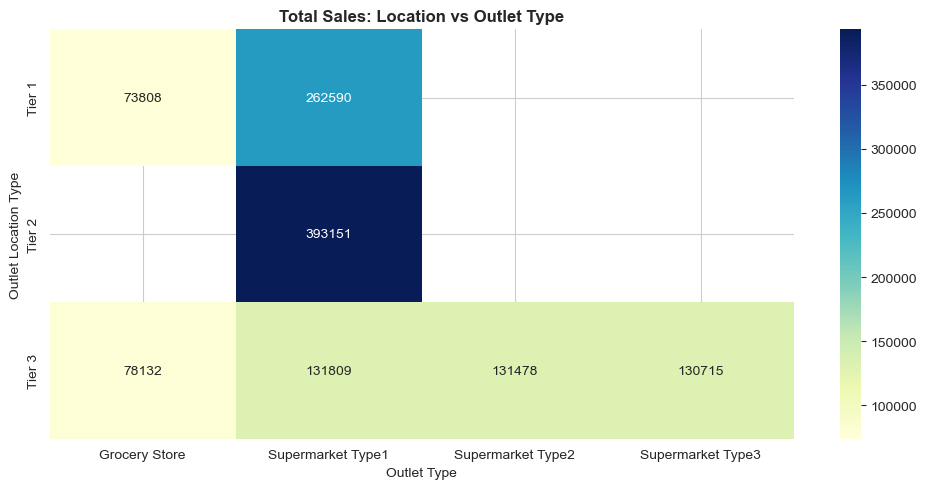

In [62]:
# Which outlet type works best in which location?
pivot = df_clean.pivot_table(values="Sales", index="Outlet Location Type",
                             columns="Outlet Type", aggfunc="sum").round(0)
print(pivot)

plt.figure(figsize=(10, 5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Total Sales: Location vs Outlet Type", fontweight="bold")
plt.tight_layout()
plt.show()

**What I found**

- The top 8 outlets are all very close, each with about 10.7% to 11.1% of the sales. OUT035, OUT046 and OUT013 lead.
- The two Grocery Stores (OUT010 and OUT019) have only about 6.5% and 6.1%.
- Tier 3 has the biggest share (39%) only because it has 4 outlets. Per outlet, Tier 2 is the highest (about 131K) and Tier 1 the lowest (about 112K).
- The tier comparison should be read carefully, because each tier has a different mix of outlet types and the Grocery Stores pull down Tier 1 and Tier 3. The outlet type matters more than the tier itself.

### Task 4.3: Identify products, outlets and areas where performance can be improved

**What this code does**

Looking for areas to improve, part A. I find the average total sales of an outlet and then calculate how far each outlet is above or below it in percent (`Gap_vs_Avg_%`). The table keeps only the outlets that are below the average.

In [63]:
print("=" * 60)
print("TASK 4.3: WHERE CAN PERFORMANCE IMPROVE?")
print("=" * 60)

# A) Outlets below the average outlet
avg_outlet_sales = outlet_sales["Total_Sales"].mean()
outlet_sales["Gap_vs_Avg_%"] = ((outlet_sales["Total_Sales"] - avg_outlet_sales) / avg_outlet_sales * 100).round(1)

weak_outlets = outlet_sales[outlet_sales["Gap_vs_Avg_%"] < 0]
weak_outlets[["Outlet Identifier", "Outlet Type", "Outlet Location Type", "Total_Sales", "Gap_vs_Avg_%"]]

TASK 4.3: WHERE CAN PERFORMANCE IMPROVE?


,Outlet Identifier,Outlet Type,Outlet Location Type,Total_Sales,Gap_vs_Avg_%
0,OUT010,Grocery Store,Tier 3,78131.5666,-35.0
4,OUT019,Grocery Store,Tier 1,73807.5824,-38.6


**What this code does**

Part B is a simple "what if" estimate. Grocery Stores have far fewer records than supermarkets. I take the average number of records of a supermarket as the target, work out how many records each Grocery Store is missing, and multiply that by the Grocery Store's own average sale. The result is only an estimate, because it assumes the extra products would sell at the same average value.

In [64]:
# B) How much could Grocery Stores add if they stocked as many products as supermarkets?
supermarkets = outlet_sales[outlet_sales["Outlet Type"] != "Grocery Store"]
groceries = outlet_sales[outlet_sales["Outlet Type"] == "Grocery Store"].copy()

target_records = supermarkets["Records"].mean()
groceries["Extra_Records_Possible"] = (target_records - groceries["Records"]).round(0)
groceries["Extra_Sales_Possible"] = (groceries["Extra_Records_Possible"] * groceries["Avg_Sales"]).round(0)

print(groceries[["Outlet Identifier", "Records", "Extra_Records_Possible", "Extra_Sales_Possible"]])
print("\nTotal extra sales possible:", groceries["Extra_Sales_Possible"].sum(),
      f"({groceries['Extra_Sales_Possible'].sum() / df_clean['Sales'].sum() * 100:.1f}% of current total)")

  Outlet Identifier  Records  Extra_Records_Possible  Extra_Sales_Possible
0            OUT010      555                   375.0               52792.0
4            OUT019      528                   402.0               56194.0

Total extra sales possible: 108986.0 (9.1% of current total)


**What this code does**

Part C compares each category's average sale with the overall average sale. The 5 categories with the lowest average sale are printed, and the chart shows the difference in percent. Red bars are below the average and green bars are above it.

Categories with the lowest average sale:
                    Avg_Sales  Records  Vs_Overall_Avg_%
Item Type                                               
Baking Goods           126.38      648             -10.4
Health and Hygiene     130.82      520              -7.2
Soft Drinks            131.49      445              -6.7
Others                 132.85      169              -5.8
Hard Drinks            137.08      214              -2.8


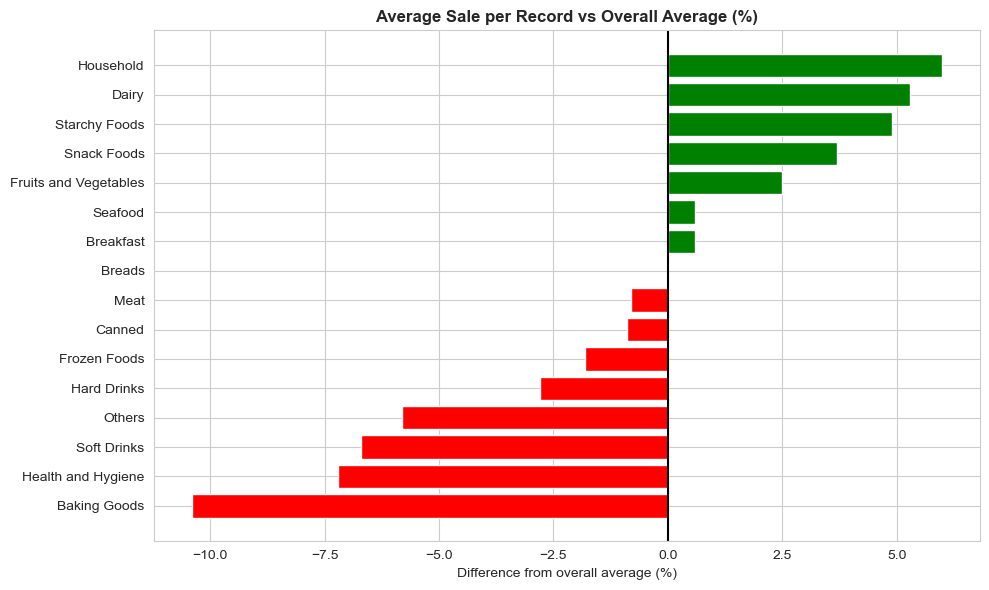

In [65]:
# C) Product categories earning less per sale than average
overall_avg = df_clean["Sales"].mean()
category_check = (
    df_clean.groupby("Item Type")
    .agg(Avg_Sales=("Sales", "mean"), Records=("Sales", "count"))
    .round(2)
)
category_check["Vs_Overall_Avg_%"] = ((category_check["Avg_Sales"] - overall_avg) / overall_avg * 100).round(1)

weak_categories = category_check.sort_values("Avg_Sales").head(5)
print("Categories with the lowest average sale:")
print(weak_categories)

# Visualization: how far each category is from the overall average
cc = category_check.sort_values("Avg_Sales")
colors = ["red" if v < 0 else "green" for v in cc["Vs_Overall_Avg_%"]]
plt.figure(figsize=(10, 6))
plt.barh(cc.index, cc["Vs_Overall_Avg_%"], color=colors)
plt.axvline(0, color="black")
plt.title("Average Sale per Record vs Overall Average (%)", fontweight="bold")
plt.xlabel("Difference from overall average (%)")
plt.tight_layout()
plt.show()

**What this code does**

Part D is a heatmap that counts the records of every category in every outlet. If a box is much smaller than the others in its row, that outlet has a thin range for that category.

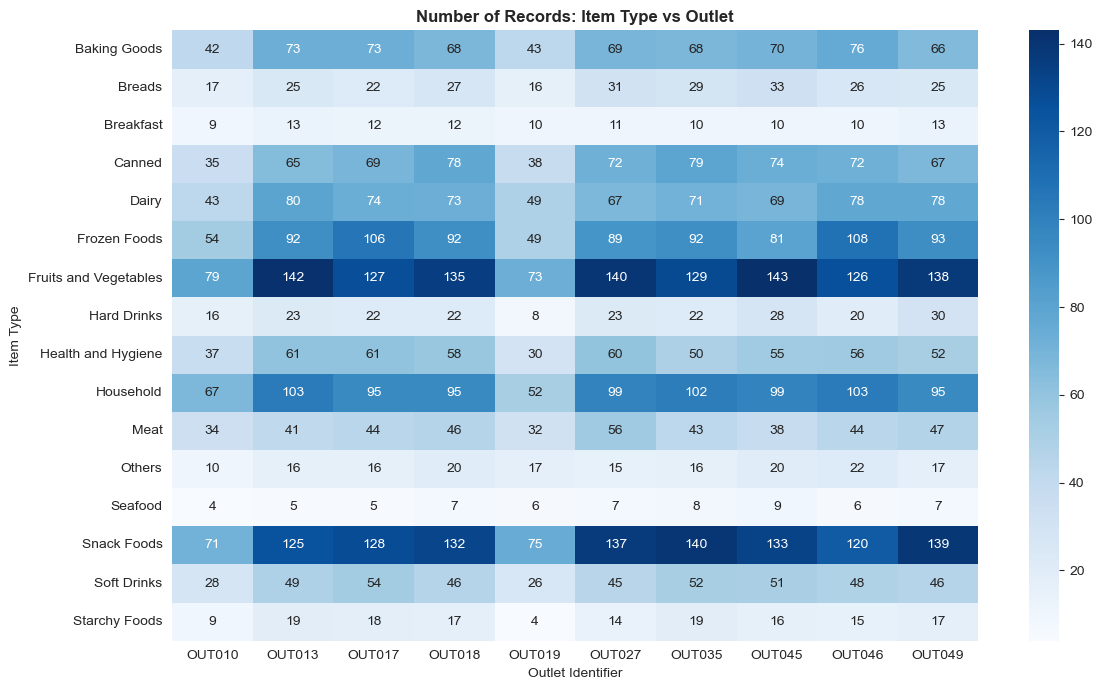

In [66]:
# D) Product range in each outlet (which outlets are thin on which categories?)
coverage = pd.crosstab(df_clean["Item Type"], df_clean["Outlet Identifier"])

plt.figure(figsize=(12, 7))
sns.heatmap(coverage, annot=True, fmt="d", cmap="Blues")
plt.title("Number of Records: Item Type vs Outlet", fontweight="bold")
plt.tight_layout()
plt.show()

**What this code does**

Part E looks for products that earn well per sale but are sold in very few outlets. I keep the products in the top 25% for average sale that are sold in 3 outlets or fewer. The last lines check the correlation between the number of outlets selling a product and its total sales.

In [67]:
# E) Products with strong sales per record but sold in very few outlets
item_view = (
    df_clean.groupby("Item Identifier")
    .agg(Item_Type=("Item Type", "first"),
         Outlets_Selling=("Outlet Identifier", "nunique"),
         Total_Sales=("Sales", "sum"),
         Avg_Sales=("Sales", "mean"))
    .reset_index()
)

high_avg_cut = item_view["Avg_Sales"].quantile(0.75)
expand_products = (
    item_view[(item_view["Outlets_Selling"] <= 3) & (item_view["Avg_Sales"] >= high_avg_cut)]
    .sort_values("Avg_Sales", ascending=False)
)

print("Products to consider stocking in more outlets:", len(expand_products))
print(expand_products.head(10))

print("\nLink between number of outlets selling a product and its total sales:")
print(item_view[["Outlets_Selling", "Total_Sales"]].corr().round(3))

Products to consider stocking in more outlets: 39
     Item Identifier           Item_Type  Outlets_Selling  Total_Sales  \
1376           NCL06           Household                3     785.6782   
685            FDN51                Meat                3     782.6808   
122            DRM11         Hard Drinks                3     782.1834   
1457           NCQ29  Health and Hygiene                3     780.6834   
1314           NCF06           Household                3     777.8886   
1524           NCW30           Household                2     517.4924   
570            FDK46         Snack Foods                3     774.8860   
742            FDP15                Meat                2     511.4660   
409            FDG28        Frozen Foods                2     492.0288   
1385           NCL42           Household                3     735.0432   

       Avg_Sales  
1376  261.892733  
685   260.893600  
122   260.727800  
1457  260.227800  
1314  259.296200  
1524  258.746200  
57

**What I found**

- **Outlets:** only the two Grocery Stores are below the average outlet (-35% and -39%). If they reached the supermarket range, the estimate is about 109K extra sales, around 9% of the current total.
- **Categories:** Baking Goods (-10.4%), Health and Hygiene (-7.2%) and Soft Drinks (-6.7%) earn the least per sale. Baking Goods is also a big category (648 records), so a small improvement there would add up.
- **Products:** 39 products have a high sale per record but are sold in 3 outlets or fewer, for example NCL06, FDN51 and DRM11.
- **Link:** the correlation between the number of outlets selling a product and its total sales is 0.53. This is the strongest relationship found in the project and supports wider distribution of the strong products.

### Task 4.4: Practical suggestions to improve sales and overall business performance

**What this code does**

This cell turns the results into business recommendations. The top part takes numbers from the earlier cells (core categories, possible extra sales, weak categories, products to expand) and stores them in variables. The `recommendations` list holds an area, a finding and an action for each point, and the `f"..."` text fills in the numbers automatically. The loop at the end prints them as a numbered list.

In [68]:
print("=" * 60)
print("TASK 4.4: BUSINESS RECOMMENDATIONS")
print("=" * 60)

core_cats = type_sales[type_sales["Class"] == "A (core)"]["Item Type"].tolist()
core_share = round(type_sales[type_sales["Class"] == "A (core)"]["Share_%"].sum(), 1)
low_cats = type_sales[type_sales["Class"] == "C (low)"]["Item Type"].tolist()
extra_sales = int(groceries["Extra_Sales_Possible"].sum())
extra_pct = round(groceries["Extra_Sales_Possible"].sum() / df_clean["Sales"].sum() * 100, 1)
weak_cat_names = ", ".join(weak_categories.index[:3])

recommendations = [
    ("Protect the core categories",
     f"{len(core_cats)} categories ({', '.join(core_cats)}) give {core_share}% of sales.",
     "Keep these always in stock in every outlet and plan inventory around them first."),

    ("Grow the Grocery Stores",
     f"OUT010 and OUT019 sell the same value per sale but carry far fewer products; an estimated {extra_sales:,} extra sales ({extra_pct}% of total) is possible.",
     "Widen the product range in Grocery Stores, starting with the Class A categories."),

    ("Improve weak-value categories",
     f"{weak_cat_names} earn the least per sale.",
     "Review pricing, pack sizes and offers, and bundle them with fast-moving items."),

    ("Expand strong products",
     f"{len(expand_products)} products with high sales per record are sold in 3 outlets or fewer.",
     "Test these products in more outlets, because wider distribution goes with higher sales."),

    ("Review low-contribution categories",
     f"{', '.join(low_cats)} make up the smallest slice of sales.",
     "Keep a smaller, focused range here and avoid overstocking."),

    ("Do not rely on visibility or weight alone",
     "Visibility, weight and rating showed almost no link with sales.",
     "Do not spend heavily on shelf-space changes without testing them first."),
]

for i, (area, finding, action) in enumerate(recommendations, 1):
    print(f"\n{i}. {area}")
    print(f"   Finding : {finding}")
    print(f"   Action  : {action}")

TASK 4.4: BUSINESS RECOMMENDATIONS

1. Protect the core categories
   Finding : 6 categories (Fruits and Vegetables, Snack Foods, Household, Frozen Foods, Dairy, Canned) give 66.6% of sales.
   Action  : Keep these always in stock in every outlet and plan inventory around them first.

2. Grow the Grocery Stores
   Finding : OUT010 and OUT019 sell the same value per sale but carry far fewer products; an estimated 108,986 extra sales (9.1% of total) is possible.
   Action  : Widen the product range in Grocery Stores, starting with the Class A categories.

3. Improve weak-value categories
   Finding : Baking Goods, Health and Hygiene, Soft Drinks earn the least per sale.
   Action  : Review pricing, pack sizes and offers, and bundle them with fast-moving items.

4. Expand strong products
   Finding : 39 products with high sales per record are sold in 3 outlets or fewer.
   Action  : Test these products in more outlets, because wider distribution goes with higher sales.

5. Review low-cont

**Notes on the recommendations**

- The 109K figure is a simple "what if" estimate. It assumes the extra products would sell at the same average value, which is not guaranteed.
- The data has no price, cost, profit or date columns. So it cannot show whether a category earns less per sale because of lower prices or lower margins, and it cannot show how sales change over time.
- The outlet and product recommendations are directional. They point to where to look first and are not exact forecasts.

## Summary

#### Objective 1: Understand the Business and Its Sales Performance

a. Products: BlinkIT sells 1,559 products across 16 categories. Fruits and Vegetables and Snack Foods have the most records.

b. Outlets: There are 10 outlets: 6 Supermarket Type1, 1 Type2, 1 Type3 and 2 Grocery Stores. They are spread across Tier 1 (3 outlets), Tier 2 (3) and Tier 3 (4).

c. Overall sales: Total sales are about 1.20 million. The average sale is about 141, ranging from 31 to 267.

d. Rating and performance: The average rating is 3.97 out of 5 and is nearly the same across categories. Fruits and Vegetables (178K) and Snack Foods (175K) lead on sales, and Seafood (9K) is lowest.

#### Objective 2: Make Sure the Available Information Is Reliable

a. Missing values: Item Weight was missing in 1,463 rows (17.2%), and 526 rows had Item Visibility of 0. Weight was filled from the same product’s other rows, and zero visibility was replaced with the product’s average visibility.

b. Duplicates: No duplicate records were found.

c. Unusual values: Sales and Weight had no outliers. 144 high Visibility values and many Rating values were flagged but kept, as they look like valid values.

d. Consistent format: Item Fat Content had 5 labels and was standardised to Low Fat and Regular, with non-consumables marked Non-Edible. Three outlets (OUT010, OUT017, OUT045) had mixed sizes, so each was given its most common size. This is an assumption to confirm with the data source.

#### Objective 3: Find Out What Is Driving Better Sales Performance

a. Products: Fruits and Vegetables, Snack Foods, Household, Frozen Foods and Dairy sell the most, and together make up about 59% of sales.

b. Outlets: Grocery Stores average about 76K per outlet, against about 131K for each supermarket type. The three supermarket types perform almost the same.

c. Connected factors: Item Visibility, Item Weight, Rating and Outlet Establishment Year all have a correlation with sales close to zero. The value per sale is about 141 in almost every group, so differences in total sales come from the number of products sold, not the value of each sale.

d. Top vs bottom: The top 25% of products are sold in about 6.6 outlets on average, against 4.7 for the bottom 25%. Visibility and rating are practically identical in both groups. The two Grocery Stores sell the same value per sale as the best outlets, but have only about 530 to 555 records against about 930.

#### Objective 4: Help Management Make Better Business Decisions

a. **Top products:** Six core categories (Fruits and Vegetables, Snack Foods, Household, Frozen Foods, Dairy and Canned) make up about 67% of sales. The top 10 products make only about 1.8%, so sales are spread widely.

b. **Top outlets and locations:** The eight supermarkets each contribute about 10.7% to 11.1% of sales, while the Grocery Stores contribute about 6.5% and 6.1%. Tier 2 is highest per outlet, but the tier differences mostly reflect which outlet types sit in each tier.

c. **Improvement areas:** The two Grocery Stores are 35% and 39% below the average outlet. Baking Goods (-10%), Health and Hygiene (-7%) and Soft Drinks (-7%) earn the least per sale. 39 high-value products are sold in 3 outlets or fewer. The number of outlets selling a product has a 0.53 correlation with its total sales, the strongest link found.

d. **Recommendations:** Keep the six core categories always in stock. Widen the product range in the Grocery Stores (estimated extra sales of about 109K, around 9% of the total, which is only an estimate). Review pricing, pack sizes and offers for the three low-value categories. Test the 39 high-performing products in more outlets. Test any shelf-visibility change before investing, as visibility showed almost no link with sales.

## Limitations

- The dataset has no price, cost, profit or date columns, so profitability and trends over time could not be analysed.
- The 109K opportunity for the Grocery Stores is a simple estimate, not a forecast.
- Outlet sizes for three outlets were corrected using the most common value, and items with an `NC` prefix were treated as non-consumables. Both are assumptions to confirm with the data source.
- With only 10 outlets, comparisons by outlet type or location are based on small groups.